# VectorGraphNet — FloorplanCAD Semantic Segmentation

Heterogeneous GAT over SVG paths with a DeepSVG-style command encoder, three
edge types (k-NN, Voronoi, weld), and three hierarchical heads (coarse / mid /
fine). Trained with focal loss on the long-tailed fine head.

**Run order**

1. `Install` &nbsp;— pip installs (run once)
2. `Setup` &nbsp;— data, model, datasets (run once per session)
3. `Train` &nbsp;— **skip if loading a pretrained checkpoint**
4. `Verify labels` &nbsp;— render a real floor plan by ground-truth class ids
5. `Results` &nbsp;— heatmaps, confusion table, B&W vs predicted vs GT, test eval

To produce images from an existing checkpoint without training, set
`CHECKPOINT_TO_LOAD` at the top of the **Results** cell and run only
`Install` → `Setup` → `Verify labels` → `Results`.


## 1. Install dependencies

Colab-friendly: PyG ships prebuilt wheels matching the active torch version.


In [ ]:
# ============================================================
# 1. Install dependencies
# ============================================================
import subprocess, sys

PACKAGES = [
    "torch_geometric",
    "svgpathtools", "lxml", "gdown",
    "scikit-learn", "tqdm",
]

for pkg in PACKAGES:
    print(f"  installing {pkg} ...", flush=True)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", pkg],
        check=True,
    )

print("\nAll dependencies installed.")


  installing torch_geometric ...
  installing svgpathtools ...
  installing lxml ...
  installing gdown ...
  installing scikit-learn ...
  installing tqdm ...

All dependencies installed.


## 2. Setup

Imports, Drive mount, dataset construction, label hierarchy, SVG parsing,
graph builder, model definition. Run once per session.


In [ ]:
# ============================================================
# 2. Setup: KNN + Weld + Delaunay Hypergraph
# ============================================================
# Three message-passing channels:
#   KNN     — pairwise GAT, k=8 nearest centroids
#   Weld    — pairwise GAT, endpoint co-location + style match
#   Delaunay — HypergraphConv over Delaunay triangles
#
# Voronoi removed (ablation showed +2.4 wF1 — we're testing whether
# Delaunay triangles can replace AND exceed that contribution by
# capturing three-way spatial groupings).
#
# Batching trick: triangles stored as a virtual 'hedge' node type
# with edges ('path','in_triangle','hedge'). PyG increments both
# path and hedge indices correctly during collation. The model
# extracts this edge_index and passes it to HypergraphConv.

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import sys, json, math, random, time, glob, zipfile, re, types
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations
from xml.etree import ElementTree as ET

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

import torch_geometric
from torch_geometric.data import Data, HeteroData, InMemoryDataset
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, HypergraphConv

import svgpathtools
from scipy.spatial import KDTree, Delaunay, QhullError
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import f1_score, classification_report
from tqdm.auto import tqdm

from IPython.display import HTML, display


def banner(title, char="="):
    line = char * 60
    print(f"\n{line}\n  {title}\n{line}")


banner("Environment")
print(f"  torch       {torch.__version__}")
print(f"  torch_geom  {torch_geometric.__version__}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"  device      {DEVICE}")
if torch.cuda.is_available():
    print(f"  gpu         {torch.cuda.get_device_name(0)}")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ==================================================================
# Drive + data
# ==================================================================
banner("Data")
from google.colab import drive
if not Path("/content/drive").is_mount():
    drive.mount("/content/drive")

DRIVE_DIR     = Path("/content/drive/MyDrive/VectorGraphNET")
DRIVE_EXTRACT = DRIVE_DIR / "extracted"
DATA_ROOT     = Path("/content/floorplancad")
DATA_ROOT.mkdir(parents=True, exist_ok=True)

SPLITS = ["test-00", "train-00", "train-01"]
for stem in SPLITS:
    dst = DATA_ROOT / stem
    if dst.exists():
        continue
    src = DRIVE_EXTRACT / stem
    if src.exists() and any(src.iterdir()):
        os.symlink(src, dst)

svg_files = []
for stem in ["train-00", "train-01"]:
    svg_files.extend(sorted((DATA_ROOT / stem).rglob("*.svg")))
test_svg_files = []
for stem in ["test-00"]:
    test_svg_files.extend(sorted((DATA_ROOT / stem).rglob("*.svg")))

print(f"  train pool : {len(svg_files):>5} SVGs")
print(f"  test  pool : {len(test_svg_files):>5} SVGs")


# ==================================================================
# Config
# ==================================================================
class CFG:
    data_root    = DATA_ROOT
    cache_dir    = Path("/content/drive/MyDrive/VectorGraphNET/pyg_cache_v4")
    val_split    = 0.10
    knn_k        = 8
    in_node_dim  = None
    in_edge_dim  = 11      # 10 base + 1 triangle co-occurrence
    hidden_dim   = 224
    num_heads    = 4
    dropout      = 0.2
    batch_size   = 6
    lr           = 15e-4
    weight_decay = 1e-4
    epochs       = 100
    grad_clip    = 1.0

CFG.cache_dir.mkdir(parents=True, exist_ok=True)

ZERO_STROKE_COLOR = False
RGB_INDICES       = (10, 11, 12)

def maybe_zero_color(batch):
    if ZERO_STROKE_COLOR:
        batch["path"].x[:, list(RGB_INDICES)] = 0.0
    return batch

_ckpt_suffix    = "_colorblind" if ZERO_STROKE_COLOR else ""
EXPERIMENT_CKPT = DRIVE_DIR / f"vgn_delaunay_hyper{_ckpt_suffix}.pt"


# ==================================================================
# Labels (corrected rotation)
# ==================================================================
FLOORPLANCAD_NAMES = {
     0: "curtain wall",  1: "railing",       2: "other",
     3: "single door",   4: "double door",   5: "sliding door",
     6: "folding door",  7: "revolving door", 8: "rolling door",
     9: "window",       10: "bay window",    11: "blind window",
    12: "opening symbol", 13: "sofa",        14: "bed",
    15: "chair",         16: "table",        17: "TV cabinet",
    18: "wardrobe",      19: "cabinet",      20: "gas stove",
    21: "sink",          22: "refrigerator", 23: "air-conditioner",
    24: "bath",          25: "bathtub",      26: "washing machine",
    27: "urinal",        28: "squat toilet", 29: "toilet",
    30: "stairs",        31: "elevator",     32: "escalator",
    33: "row chairs",    34: "parking spot", 35: "wall",
}
N_FINE = len(FLOORPLANCAD_NAMES)

MID_GROUPS = {
    "door": [3,4,5,6,7,8], "window": [9,10,11,12],
    "seating": [13,15,33], "sleeping": [14], "surface": [16],
    "storage": [17,18,19], "kitchen": [20,21,22], "climate": [23],
    "bath": [24,25], "laundry": [26], "sanitary": [27,28,29],
    "circulation": [30,31,32], "parking": [34],
    "wall": [0,35], "railing": [1], "other": [2],
}
MID_NAMES  = sorted(MID_GROUPS.keys())
MID_TO_IDX = {n: i for i, n in enumerate(MID_NAMES)}
N_MID      = len(MID_NAMES)

COARSE_GROUPS = {
    "opening":   ["door", "window"],
    "furniture": ["seating","sleeping","surface","storage",
                  "kitchen","climate","bath","laundry","sanitary"],
    "structure": ["wall","railing","circulation","parking"],
    "other":     ["other"],
}
COARSE_NAMES  = sorted(COARSE_GROUPS.keys())
COARSE_TO_IDX = {n: i for i, n in enumerate(COARSE_NAMES)}
N_COARSE      = len(COARSE_NAMES)

FINE_TO_MID    = {fid: MID_TO_IDX[mid]
                  for mid, fids in MID_GROUPS.items() for fid in fids}
MID_TO_COARSE  = {MID_TO_IDX[mn]: COARSE_TO_IDX[cn]
                   for cn, mns in COARSE_GROUPS.items() for mn in mns}
FINE_TO_COARSE = {fid: MID_TO_COARSE[m] for fid, m in FINE_TO_MID.items()}

_unmapped = [fid for fid in FLOORPLANCAD_NAMES if fid not in FINE_TO_MID]
if _unmapped:
    raise RuntimeError(f"Unmapped: {_unmapped}")

print(f"  fine: {N_FINE}  mid: {N_MID}  coarse: {N_COARSE}")


# ==================================================================
# SVG parser + features + cmd tokenizer
# ==================================================================
COMMAND_TYPES    = ["M","L","H","V","C","Q","A","Z"]
NODE_FEATURE_DIM = 30
N_CURVE_SAMPLES  = 8
MAX_CMDS = 64; CMD_DIM = 8; PAD_VALUE = -1.0
CMD_TO_IDX  = {"PAD":0,"M":1,"L":2,"C":3,"Q":4,"A":5,"Z":6}
N_CMD_TYPES = len(CMD_TO_IDX)

def _safe_log(x, eps=1e-6):
    return float(np.log(max(abs(float(x)), eps)))

def _parse_color(s):
    if not s or s == "none": return (0.,0.,0.)
    s = s.strip()
    if s.startswith("#"):
        h = s[1:]
        if len(h)==3: r,g,b = (int(h[i]*2,16) for i in range(3))
        elif len(h)==6: r,g,b = int(h[0:2],16),int(h[2:4],16),int(h[4:6],16)
        else: return (0.,0.,0.)
        return (r/255.,g/255.,b/255.)
    m = re.match(r"rgb\((\d+),\s*(\d+),\s*(\d+)\)", s)
    if m: return tuple(int(m.group(i+1))/255. for i in range(3))
    return (0.,0.,0.)

def _extract_vertices(path):
    pts = []
    for seg in path:
        pts.append((seg.start.real, seg.start.imag))
        pts.append((seg.end.real,   seg.end.imag))
    if not pts: return np.zeros((0,2), dtype=np.float32)
    pts = np.array(pts, dtype=np.float32)
    if len(pts) > 1:
        d = np.linalg.norm(np.diff(pts, axis=0), axis=1)
        pts = pts[np.concatenate([[True], d > 1e-8])]
    return pts

def parse_svg_paths(svg_path):
    tree = ET.parse(svg_path); out = []
    for elem in tree.getroot().iter():
        if elem.tag.split("}")[-1] != "path": continue
        d = elem.get("d")
        if not d: continue
        sem_raw = elem.get("semantic-id") or elem.get("semanticId")
        inst_raw = elem.get("instance-id") or elem.get("instanceId")
        if sem_raw is None: sem, inst = 2, -1
        else:
            try:
                sem = int(sem_raw)
                inst = int(inst_raw) if inst_raw is not None else -1
            except ValueError: sem, inst = 2, -1
        try: sw = float(elem.get("stroke-width") or "1")
        except ValueError: sw = 1.0
        out.append({"d": d, "semantic_id": sem, "instance_id": inst,
                    "stroke_width": sw,
                    "stroke_rgb": _parse_color(elem.get("stroke") or ""),
                    "has_fill": 0. if (elem.get("fill") or "none")=="none" else 1.})
    return out

def _count_commands(d_string):
    counts = {c:0 for c in COMMAND_TYPES}
    for ch in d_string:
        u = ch.upper()
        if u in counts: counts[u] += 1
    return [counts[c] for c in COMMAND_TYPES]

def _norm_coord(v, off, scl):
    return (v-off)/scl if scl > 1e-8 else 0.

def path_to_cmd_tensor(path_obj, bbox):
    xmin,ymin,xmax,ymax = bbox
    scl = max(max(xmax-xmin,1e-8), max(ymax-ymin,1e-8))
    rows = []
    if len(path_obj) > 0:
        s0 = path_obj[0].start
        r = np.full(CMD_DIM, PAD_VALUE, dtype=np.float32)
        r[0]=CMD_TO_IDX["M"]; r[1]=_norm_coord(s0.real,xmin,scl); r[2]=_norm_coord(s0.imag,ymin,scl)
        rows.append(r)
    for seg in path_obj:
        r = np.full(CMD_DIM, PAD_VALUE, dtype=np.float32)
        if isinstance(seg, svgpathtools.Line):
            r[0]=CMD_TO_IDX["L"]; r[1]=_norm_coord(seg.end.real,xmin,scl); r[2]=_norm_coord(seg.end.imag,ymin,scl)
        elif isinstance(seg, svgpathtools.CubicBezier):
            r[0]=CMD_TO_IDX["C"]
            r[1]=_norm_coord(seg.control1.real,xmin,scl); r[2]=_norm_coord(seg.control1.imag,ymin,scl)
            r[3]=_norm_coord(seg.control2.real,xmin,scl); r[4]=_norm_coord(seg.control2.imag,ymin,scl)
            r[5]=_norm_coord(seg.end.real,xmin,scl); r[6]=_norm_coord(seg.end.imag,ymin,scl)
        elif isinstance(seg, svgpathtools.QuadraticBezier):
            r[0]=CMD_TO_IDX["Q"]
            r[1]=_norm_coord(seg.control.real,xmin,scl); r[2]=_norm_coord(seg.control.imag,ymin,scl)
            r[3]=_norm_coord(seg.end.real,xmin,scl); r[4]=_norm_coord(seg.end.imag,ymin,scl)
        elif isinstance(seg, svgpathtools.Arc):
            r[0]=CMD_TO_IDX["A"]; r[1]=seg.radius.real/scl; r[2]=seg.radius.imag/scl
            r[3]=seg.rotation/360.; r[4]=float(seg.large_arc); r[5]=float(seg.sweep)
            r[6]=_norm_coord(seg.end.real,xmin,scl); r[7]=_norm_coord(seg.end.imag,ymin,scl)
        else: continue
        rows.append(r)
    if len(path_obj)>0 and path_obj.isclosed():
        r = np.full(CMD_DIM, PAD_VALUE, dtype=np.float32); r[0]=CMD_TO_IDX["Z"]; rows.append(r)
    rows = rows[:MAX_CMDS]
    out = np.full((MAX_CMDS, CMD_DIM), PAD_VALUE, dtype=np.float32)
    for i,r in enumerate(rows): out[i] = r
    return out

def path_features(path_dict):
    try: path = svgpathtools.parse_path(path_dict["d"])
    except: return None
    if len(path)==0: return None
    try: xmin,xmax,ymin,ymax = path.bbox()
    except: return None
    cx=.5*(xmin+xmax); cy=.5*(ymin+ymax); w=max(xmax-xmin,1e-6); h=max(ymax-ymin,1e-6)
    try: length=float(path.length(error=1e-2))
    except: length=0.
    n_seg=len(path); n_lines=sum(1 for s in path if isinstance(s,svgpathtools.Line))
    n_curves=n_seg-n_lines; is_closed=float(path.isclosed()) if n_seg>1 else 0.
    vertices = _extract_vertices(path)
    if len(vertices)==0: vertices = np.array([[cx,cy]], dtype=np.float32)
    sample_pts = np.full((N_CURVE_SAMPLES,2), [cx,cy], dtype=np.float32)
    if n_seg>0 and length>0:
        for k,t in enumerate(np.linspace(0,1,N_CURVE_SAMPLES)):
            try: p=path.point(t); sample_pts[k,0]=p.real; sample_pts[k,1]=p.imag
            except: pass
    area=0.
    if is_closed and len(vertices)>=3:
        try: area=float(abs(.5*np.sum(vertices[:-1,0]*vertices[1:,1]-vertices[1:,0]*vertices[:-1,1])))
        except: pass
    sw=path_dict["stroke_width"]; r,g,b=path_dict["stroke_rgb"]
    has_fill=path_dict["has_fill"]; cmd_counts=_count_commands(path_dict["d"])
    mean_c,max_c = 0.,0.
    if N_CURVE_SAMPLES>=3:
        d1=np.diff(sample_pts,axis=0); d2=np.diff(d1,axis=0)
        num=np.abs(d1[:-1,0]*d2[:,1]-d1[:-1,1]*d2[:,0])
        den=np.linalg.norm(d1[:-1],axis=1)**3+1e-9
        curv=num/den; mean_c,max_c=float(curv.mean()),float(curv.max())
    try:
        p0=path.point(0.); p1=path.point(1.)
        endpoints=((float(p0.real),float(p0.imag)),(float(p1.real),float(p1.imag)))
    except: endpoints=((cx,cy),(cx,cy))
    feats = np.array([
        cx,cy,w,h,_safe_log(w),_safe_log(h), length,_safe_log(length),
        sw,_safe_log(sw),r,g,b,has_fill, n_seg,is_closed,n_lines,n_curves,
        area,_safe_log(area+1.), mean_c,max_c, *cmd_counts,
    ], dtype=np.float32)
    return {"feat":feats, "bbox":(xmin,ymin,xmax,ymax), "center":(cx,cy),
            "length":length, "stroke_width":sw, "stroke_rgb":(r,g,b),
            "has_fill":has_fill, "is_closed":is_closed, "vertices":vertices,
            "sample_pts":sample_pts, "endpoints":endpoints,
            "cmd_tensor":path_to_cmd_tensor(path,(xmin,ymin,xmax,ymax))}


# ==================================================================
# Graph edges: KNN + Weld + Delaunay triangles
# ==================================================================
KNN_K            = 8
WELD_EPS_FRAC    = 1e-3
EDGE_FEATURE_DIM = 10   # base pairwise features (triangle count appended as 11th)

def _style_compatible(fa, fb, sw_tol=0.05, rgb_tol=0.1):
    if abs(fa["stroke_width"]-fb["stroke_width"]) > sw_tol: return False
    ra,ga,ba = fa["stroke_rgb"]; rb,gb,bb = fb["stroke_rgb"]
    return (abs(ra-rb)+abs(ga-gb)+abs(ba-bb)) <= rgb_tol

def build_weld_edges(features, eps_abs):
    if len(features)<2: return np.zeros((2,0), dtype=np.int64)
    endpoints, owners = [], []
    for i,f in enumerate(features):
        for ep in f["endpoints"]: endpoints.append(ep); owners.append(i)
    endpoints = np.array(endpoints, dtype=np.float32); owners = np.array(owners)
    pairs = KDTree(endpoints).query_pairs(r=eps_abs, output_type="ndarray")
    welded = set()
    for a,b in pairs:
        i,j = int(owners[a]), int(owners[b])
        if i!=j and _style_compatible(features[i], features[j]):
            welded.add((min(i,j), max(i,j)))
    if not welded: return np.zeros((2,0), dtype=np.int64)
    src,dst = [],[]
    for i,j in welded: src+=[i,j]; dst+=[j,i]
    return np.array([src,dst], dtype=np.int64)


def build_delaunay_triangles(features, min_triangle_count=1):
    """Delaunay triangulation over all path vertices.

    Returns:
        hyperedge_index: (2, M) — row 0 = path (node) indices,
                                   row 1 = triangle (hyperedge) indices.
                         Suitable for HypergraphConv.
        num_triangles:   int — number of unique path-level triangles.
        tri_pair_counts: dict (a,b) → int — pairwise triangle
                         co-occurrence counts for edge features.
    """
    n = len(features)
    if n < 4:
        return np.zeros((2, 0), dtype=np.int64), 0, {}

    all_v, owner = [], []
    for i, f in enumerate(features):
        v = f["vertices"]; all_v.append(v); owner.extend([i] * len(v))
    all_v = np.concatenate(all_v, axis=0)
    owner = np.array(owner, dtype=np.int64)

    if len(all_v) < 4:
        return np.zeros((2, 0), dtype=np.int64), 0, {}

    jitter = np.random.default_rng(42).normal(0, 1e-8, all_v.shape).astype(np.float32)
    try:
        tri = Delaunay(all_v + jitter, qhull_options="Qbb Qc Qz")
    except (QhullError, ValueError):
        return np.zeros((2, 0), dtype=np.int64), 0, {}

    # Count path-level triangle occurrences and pairwise co-occurrences
    path_triangles = Counter()
    tri_pair_counts = defaultdict(int)

    for simplex in tri.simplices:
        paths_in_tri = frozenset(int(owner[v]) for v in simplex)
        if len(paths_in_tri) < 2:
            continue
        for a, b in combinations(sorted(paths_in_tri), 2):
            tri_pair_counts[(a, b)] += 1
        if len(paths_in_tri) == 3:
            path_triangles[paths_in_tri] += 1

    # Build hyperedge_index from triangles above threshold
    node_ids, hedge_ids = [], []
    hedge_idx = 0
    for tri_set, count in path_triangles.items():
        if count < min_triangle_count:
            continue
        for node in sorted(tri_set):
            node_ids.append(node)
            hedge_ids.append(hedge_idx)
        hedge_idx += 1

    if not node_ids:
        return np.zeros((2, 0), dtype=np.int64), 0, dict(tri_pair_counts)

    hyper_ei = np.array([node_ids, hedge_ids], dtype=np.int64)
    return hyper_ei, hedge_idx, dict(tri_pair_counts)


def _compute_edge_features(features, edge_index, bbox_diag, tri_pair_counts=None):
    """10 or 11-dim edge features."""
    E = edge_index.shape[1]
    has_tri = tri_pair_counts is not None and len(tri_pair_counts) > 0
    out_dim = EDGE_FEATURE_DIM + (1 if has_tri else 0)
    if E == 0:
        return np.zeros((0, out_dim), dtype=np.float32)

    si, di = edge_index[0], edge_index[1]
    centers = np.array([f["center"] for f in features], dtype=np.float32)
    lengths = np.array([f["length"] for f in features], dtype=np.float32)
    bboxes  = np.array([f["bbox"]   for f in features], dtype=np.float32)
    closed  = np.array([f["is_closed"] for f in features], dtype=np.float32)
    endpts  = np.array([f["endpoints"] for f in features], dtype=np.float32)
    sws     = np.array([f["stroke_width"] for f in features], dtype=np.float32)
    rgbs    = np.array([f["stroke_rgb"]   for f in features], dtype=np.float32)

    n_nodes = len(features); vc = [len(f["vertices"]) for f in features]; max_v = max(vc)
    if n_nodes * max_v * max_v < 10_000_000:
        padded = np.full((n_nodes, max_v, 2), 1e9, dtype=np.float32)
        for i,f in enumerate(features): v=f["vertices"]; padded[i,:len(v)]=v
        va=padded[si]; vb=padded[di]
        diff=va[:,:,None,:]-vb[:,None,:,:]
        min_seps=np.linalg.norm(diff,axis=-1).min(axis=(1,2)).astype(np.float32)
    else:
        unique = set()
        for k in range(E): a,b=int(si[k]),int(di[k]); unique.add((min(a,b),max(a,b)))
        pmd = {}
        for a,b in unique:
            va,vb = features[a]["vertices"], features[b]["vertices"]
            if len(va)==0 or len(vb)==0: pmd[(a,b)]=1e6; continue
            small,big = (va,vb) if len(va)<=len(vb) else (vb,va)
            if len(big)<20:
                d=small[:,None,:]-big[None,:,:]; pmd[(a,b)]=float(np.linalg.norm(d,axis=-1).min())
            else:
                t=KDTree(big); d,_=t.query(small,k=1); pmd[(a,b)]=float(np.min(d))
        min_seps = np.array([pmd[(min(int(si[k]),int(di[k])),max(int(si[k]),int(di[k])))]
                             for k in range(E)], dtype=np.float32)

    spts=np.stack([f["sample_pts"] for f in features],axis=0)
    sa=spts[si]; sb=spts[di]; diff_s=sa[:,:,None,:]-sb[:,None,:,:]
    pairwise_s=np.linalg.norm(diff_s,axis=-1)
    n_intersect=(pairwise_s < bbox_diag*1e-3).sum(axis=(1,2)).astype(np.float32)

    sw_match=np.abs(sws[si]-sws[di])<=0.05
    rgb_diff=np.abs(rgbs[si]-rgbs[di]).sum(axis=1)
    style=(sw_match & (rgb_diff<=0.1)).astype(np.float32)

    cs=centers[si]; cd=centers[di]; ds=cs-cd; cdist=np.linalg.norm(ds,axis=1)
    ea=endpts[si]; eb=endpts[di]; diff_ep=ea[:,:,None,:]-eb[:,None,:,:]
    d_ep=np.linalg.norm(diff_ep,axis=-1).min(axis=(1,2))
    bs=bboxes[si]; bd=bboxes[di]
    sc=closed[si]>0.5; dc=closed[di]>0.5
    incl=((sc&(bs[:,0]<=cd[:,0])&(cd[:,0]<=bs[:,2])&(bs[:,1]<=cd[:,1])&(cd[:,1]<=bs[:,3]))|
          (dc&(bd[:,0]<=cs[:,0])&(cs[:,0]<=bd[:,2])&(bd[:,1]<=cs[:,1])&(cs[:,1]<=bd[:,3]))).astype(np.float32)

    feats = np.zeros((E, out_dim), dtype=np.float32)
    feats[:,0] = np.minimum(cdist/max(bbox_diag,1e-6), 1.)
    feats[:,1] = (np.abs(lengths[si]-lengths[di])<1e-3).astype(np.float32)
    feats[:,2] = np.log(np.maximum(min_seps, 1e-6))
    feats[:,3] = n_intersect
    feats[:,4] = style
    feats[:,5] = incl
    feats[:,6] = (d_ep < bbox_diag*WELD_EPS_FRAC).astype(np.float32)
    feats[:,7] = np.arctan2(ds[:,1], ds[:,0])/np.pi
    feats[:,8] = np.log(np.maximum(lengths[si],1e-6)/np.maximum(lengths[di],1e-6))
    feats[:,9] = np.minimum(np.maximum(lengths[si],1e-6)/np.maximum(lengths[di],1e-6), 100.)
    if has_tri:
        for k in range(E):
            a,b = int(si[k]),int(di[k]); key=(min(a,b),max(a,b))
            feats[k,10] = np.log(tri_pair_counts.get(key, 0) + 1)
    return feats


def _build_one_graph(svg_path):
    try:
        raw = parse_svg_paths(svg_path)
        features, cmd_tensors, labels = [], [], []
        for p in raw:
            f = path_features(p)
            if f is None: continue
            features.append(f); cmd_tensors.append(f["cmd_tensor"])
            labels.append(p["semantic_id"])
        n = len(features)
        if n < KNN_K + 1: return None

        X = np.stack([f["feat"] for f in features])
        Y = np.array(labels, dtype=np.int64)
        centers = np.array([f["center"] for f in features], dtype=np.float32)
        cmin=centers.min(axis=0); cmax=centers.max(axis=0)
        span = float(max(cmax[0]-cmin[0], cmax[1]-cmin[1], 1e-6))
        bbox_diag = float(np.linalg.norm(cmax-cmin))
        cn=(centers-cmin)/span
        X[:,0]=cn[:,0]; X[:,1]=cn[:,1]; X[:,2]/=span; X[:,3]/=span

        # KNN
        nn = NearestNeighbors(n_neighbors=min(KNN_K+1, n)).fit(cn)
        _,idx = nn.kneighbors(cn)
        src,dst = [],[]
        for i in range(n):
            for j in idx[i,1:]: src.append(i); dst.append(int(j))
        knn_ei = np.array([src,dst], dtype=np.int64)

        # Weld
        weld_ei = build_weld_edges(features, eps_abs=bbox_diag*WELD_EPS_FRAC)

        # Delaunay triangles (hyperedges + pairwise counts)
        hyper_ei, num_triangles, tri_pair_counts = build_delaunay_triangles(features)

        # Edge features (11-dim: 10 base + triangle co-occurrence)
        knn_ef  = _compute_edge_features(features, knn_ei,  bbox_diag, tri_pair_counts)
        weld_ef = _compute_edge_features(features, weld_ei, bbox_diag, tri_pair_counts)

        d = HeteroData()
        d["path"].x          = torch.from_numpy(X).float()
        d["path"].y          = torch.from_numpy(Y).long()
        d["path"].cmd_tensor = torch.from_numpy(np.stack(cmd_tensors)).float()

        # Pairwise edges
        d["path","knn","path"].edge_index  = torch.from_numpy(knn_ei).long()
        d["path","knn","path"].edge_attr   = torch.from_numpy(knn_ef).float()
        d["path","weld","path"].edge_index = torch.from_numpy(weld_ei).long()
        d["path","weld","path"].edge_attr  = torch.from_numpy(weld_ef).float()

        # Hyperedges via virtual 'hedge' node type
        # PyG increments row 0 by cumulative 'path' count and
        # row 1 by cumulative 'hedge' count during batching.
        d["hedge"].x = torch.zeros(num_triangles, 1)  # dummy feature for PyG slicing
        if hyper_ei.shape[1] > 0:
            d["path","in_triangle","hedge"].edge_index = torch.from_numpy(hyper_ei).long()
        else:
            d["path","in_triangle","hedge"].edge_index = torch.zeros((2,0), dtype=torch.long)

        return d
    except Exception:
        return None


# ==================================================================
# Dataset
# ==================================================================
class FloorplanCADDataset(InMemoryDataset):
    def __init__(self, root, svg_paths, fine_to_mid, fine_to_coarse,
                 force_reprocess=False, transform=None):
        self._svg_paths      = [str(p) for p in svg_paths]
        self._fine_to_mid    = fine_to_mid
        self._fine_to_coarse = fine_to_coarse
        if force_reprocess:
            proc = Path(root)/"processed"
            if proc.exists():
                for p in proc.iterdir(): p.unlink()
        super().__init__(root, transform)
        self.load(self.processed_paths[0])

    @property
    def processed_file_names(self):
        return ["data.pt"]

    def process(self):
        graphs, skipped = [], 0
        t0 = time.time()
        for svg_str in tqdm(self._svg_paths, desc="building graphs"):
            d = _build_one_graph(svg_str)
            if d is None: skipped += 1; continue
            fine = d["path"].y.numpy()
            mid  = np.array([self._fine_to_mid.get(int(c), MID_TO_IDX["other"])
                             for c in fine], dtype=np.int64)
            coar = np.array([self._fine_to_coarse.get(int(c), COARSE_TO_IDX["other"])
                             for c in fine], dtype=np.int64)
            d["path"].y_fine   = d["path"].y
            d["path"].y_mid    = torch.from_numpy(mid).long()
            d["path"].y_coarse = torch.from_numpy(coar).long()
            graphs.append(d)
        if not graphs: raise RuntimeError("No valid graphs.")
        self.save(graphs, self.processed_paths[0])
        print(f"  saved {len(graphs)} in {(time.time()-t0)/60:.1f} min ({skipped} skipped)")


banner("Datasets")
random.shuffle(svg_files)
n_val = max(1, int(len(svg_files)*CFG.val_split))
val_svgs   = svg_files[:n_val]
train_svgs = svg_files[n_val:]
print(f"  train: {len(train_svgs)}  val: {len(val_svgs)}  test: {len(test_svg_files)}")

train_ds = FloorplanCADDataset(
    root=str(CFG.cache_dir/"train"), svg_paths=train_svgs,
    fine_to_mid=FINE_TO_MID, fine_to_coarse=FINE_TO_COARSE)
val_ds = FloorplanCADDataset(
    root=str(CFG.cache_dir/"val"), svg_paths=val_svgs,
    fine_to_mid=FINE_TO_MID, fine_to_coarse=FINE_TO_COARSE)
test_ds = FloorplanCADDataset(
    root=str(CFG.cache_dir/"test"), svg_paths=test_svg_files,
    fine_to_mid=FINE_TO_MID, fine_to_coarse=FINE_TO_COARSE)
print(f"  train: {len(train_ds)}  val: {len(val_ds)}  test: {len(test_ds)}")

sample = train_ds[0]
knn_e  = sample["path","knn","path"].edge_index.shape[1]
weld_e = sample["path","weld","path"].edge_index.shape[1]
tri_e  = sample["path","in_triangle","hedge"].edge_index.shape[1]
n_tri = sample["hedge"].x.shape[0]  # was .num_nodes
ef_dim = sample["path","knn","path"].edge_attr.shape[1]
print(f"\n  sample: {sample['path'].num_nodes} nodes, feat {sample['path'].x.shape[1]}")
print(f"  knn edges:  {knn_e}   weld edges: {weld_e}")
print(f"  triangles:  {n_tri}   (entries: {tri_e})")
print(f"  edge feat:  {ef_dim}-dim")


# ==================================================================
# Model: KNN GAT + Weld GAT + Delaunay HypergraphConv
# ==================================================================
class SVGCommandEncoder(nn.Module):
    def __init__(self, n_cmd_types=N_CMD_TYPES, n_params=7,
                 cmd_embed_dim=16, param_proj_dim=16,
                 conv_channels=64, embed_dim=32):
        super().__init__()
        self.embed_dim  = embed_dim
        self.cmd_embed  = nn.Embedding(n_cmd_types, cmd_embed_dim, padding_idx=0)
        self.param_proj = nn.Linear(n_params, param_proj_dim)
        token_dim       = cmd_embed_dim + param_proj_dim
        self.conv = nn.Sequential(
            nn.Conv1d(token_dim, conv_channels, 3, padding=1), nn.ReLU(),
            nn.Conv1d(conv_channels, conv_channels, 3, padding=1), nn.ReLU(),
        )
        self.out_proj = nn.Linear(conv_channels, embed_dim)

    def forward(self, cmd_tensor):
        cmd_idx = cmd_tensor[:,:,0].long().clamp(min=0)
        params  = cmd_tensor[:,:,1:].clone(); params[params<-0.5]=0.
        tokens = torch.cat([self.cmd_embed(cmd_idx), self.param_proj(params)], dim=-1)
        mask   = (cmd_tensor[:,:,0]>=0).float().unsqueeze(-1)
        x = self.conv(tokens.permute(0,2,1)).permute(0,2,1) * mask
        return self.out_proj(x.sum(dim=1) / mask.sum(dim=1).clamp(min=1.))


class VectorGraphNetHetero(nn.Module):
    """KNN GAT + Weld GAT + Delaunay HypergraphConv per layer."""

    def __init__(self, in_node_dim, in_edge_dim,
                 n_coarse, n_mid, n_fine,
                 hidden_dim=192, num_heads=4, dropout=0.2,
                 cmd_embed_dim=32,
                 pairwise_types=("knn", "weld")):
        super().__init__()
        self.pw_types    = tuple(pairwise_types)
        self.cmd_encoder = SVGCommandEncoder(embed_dim=cmd_embed_dim)
        self.input_proj  = nn.Linear(in_node_dim + cmd_embed_dim, hidden_dim)

        out_dim = hidden_dim * num_heads

        # Layer 1
        self.gat1 = nn.ModuleDict({
            et: GATv2Conv(hidden_dim, hidden_dim, heads=num_heads,
                          edge_dim=in_edge_dim, dropout=dropout,
                          concat=True, add_self_loops=False)
            for et in self.pw_types
        })
        self.hyper1 = HypergraphConv(hidden_dim, out_dim, dropout=dropout)

        # Layer 2
        self.gat2 = nn.ModuleDict({
            et: GATv2Conv(out_dim, hidden_dim, heads=num_heads,
                          edge_dim=in_edge_dim, dropout=dropout,
                          concat=True, add_self_loops=False)
            for et in self.pw_types
        })
        self.hyper2 = HypergraphConv(out_dim, out_dim, dropout=dropout)

        self.head_coarse = nn.Linear(out_dim, n_coarse)
        self.head_mid    = nn.Linear(out_dim, n_mid)
        self.head_fine   = nn.Linear(out_dim, n_fine)
        self.drop        = nn.Dropout(dropout)

    def _aggregate(self, gat_dict, hyper_layer, h, data):
        outs = []

        # Pairwise GAT channels
        for et in self.pw_types:
            ei = data["path", et, "path"].edge_index
            ea = data["path", et, "path"].edge_attr
            if ei.numel() == 0:
                continue
            if self.training:
                outs.append(checkpoint(
                    lambda x, eidx, eattr, lyr=gat_dict[et]:
                        lyr(x, eidx, edge_attr=eattr),
                    h, ei, ea, use_reentrant=False))
            else:
                outs.append(gat_dict[et](h, ei, edge_attr=ea))

        # Hypergraph channel (Delaunay triangles)
        hyper_idx = data["path", "in_triangle", "hedge"].edge_index
        if hyper_idx.numel() > 0:
            if self.training:
                outs.append(checkpoint(
                    lambda x, hidx, lyr=hyper_layer: lyr(x, hidx),
                    h, hyper_idx, use_reentrant=False))
            else:
                outs.append(hyper_layer(h, hyper_idx))

        return torch.stack(outs, dim=0).mean(dim=0) if outs else h

    def forward(self, data):
        x_geom = data["path"].x
        x_cmd  = self.cmd_encoder(data["path"].cmd_tensor)
        h = F.relu(self.input_proj(torch.cat([x_geom, x_cmd], dim=-1)))
        h = self.drop(F.relu(self._aggregate(self.gat1, self.hyper1, h, data)))
        h = self.drop(F.relu(self._aggregate(self.gat2, self.hyper2, h, data)))
        return {"coarse": self.head_coarse(h),
                "mid":    self.head_mid(h),
                "fine":   self.head_fine(h)}


banner("Model")
CFG.in_node_dim = train_ds[0]["path"].x.shape[1]

model = VectorGraphNetHetero(
    in_node_dim=CFG.in_node_dim, in_edge_dim=CFG.in_edge_dim,
    n_coarse=N_COARSE, n_mid=N_MID, n_fine=N_FINE,
    hidden_dim=CFG.hidden_dim, num_heads=CFG.num_heads,
    dropout=CFG.dropout, cmd_embed_dim=32,
    pairwise_types=("knn", "weld"),
).to(DEVICE)

n_total = sum(p.numel() for p in model.parameters())
n_enc   = sum(p.numel() for p in model.cmd_encoder.parameters())
n_hyp   = sum(p.numel() for p in model.hyper1.parameters()) + \
          sum(p.numel() for p in model.hyper2.parameters())
print(f"  in_node_dim  : {CFG.in_node_dim}")
print(f"  in_edge_dim  : {CFG.in_edge_dim}")
print(f"  total params : {n_total/1e6:.2f}M")
print(f"    cmd encoder: {n_enc/1e3:.1f}K")
print(f"    GAT layers : {(n_total-n_enc-n_hyp)/1e6:.2f}M")
print(f"    hypergraph : {n_hyp/1e3:.1f}K")

display(HTML(
    "<div style='padding:8px 12px;background:#1f2937;color:#e5e7eb;"
    "border-left:4px solid #10b981;font-family:monospace;'>"
    "Setup complete (Delaunay hypergraph, no Voronoi). Ready to train.</div>"))


  Environment
  torch       2.10.0+cu128
  torch_geom  2.7.0
  device      cuda
  gpu         NVIDIA RTX PRO 6000 Blackwell Server Edition

  Data
Mounted at /content/drive
  train pool : 10161 SVGs
  test  pool :  5502 SVGs
  fine: 36  mid: 16  coarse: 4

  Datasets
  train: 9145  val: 1016  test: 5502
  train: 9138  val: 1016  test: 5494

  sample: 851 nodes, feat 30
  knn edges:  6808   weld edges: 4154
  triangles:  1192   (entries: 3576)
  edge feat:  11-dim

  Model
  in_node_dim  : 30
  in_edge_dim  : 11
  total params : 5.16M
    cmd encoder: 20.9K
    GAT layers : 4.13M
    hypergraph : 1005.3K


## 3. Train

Focal loss on the fine head (γ=2.0, no class weights), CE on coarse/mid.
Best checkpoint by val weighted-F1 is saved to `EXPERIMENT_CKPT` (defined
in the Setup cell).

**Skip this cell** if you set `CHECKPOINT_TO_LOAD` in the Results cell to
load a pretrained model from Drive.


In [ ]:
# ============================================================
# 3. Train: Delaunay hypergraph experiment
# ============================================================

USE_CLASS_WEIGHTS = False
GAMMA             = 1.5
FLOOR             = 0.3
MIN_SUPPORT       = 50
LOSS_WEIGHTS      = {"coarse": 0.2, "mid": 0.3, "fine": 0.5}
ACCUM_STEPS       = 2
PATIENCE          = 40
MIN_DELTA         = 1e-4
TOP_K             = 3
RESUME            = EXPERIMENT_CKPT.exists()


class FocalLoss(nn.Module):
    def __init__(self, weight=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.weight = weight; self.gamma = gamma; self.reduction = reduction
    def forward(self, logits, target):
        lp = F.log_softmax(logits, dim=-1); pr = lp.exp()
        lpt = lp.gather(1, target.unsqueeze(1)).squeeze(1)
        pt  = pr.gather(1, target.unsqueeze(1)).squeeze(1)
        loss = -((1-pt)**self.gamma) * lpt
        if self.weight is not None:
            loss = loss * self.weight.gather(0, target)
        return loss.mean() if self.reduction=="mean" else (
            loss.sum() if self.reduction=="sum" else loss)


def _compute_weights(graphs, attr, n_classes, floor=FLOOR, min_support=MIN_SUPPORT):
    counts = np.zeros(n_classes, dtype=np.float64)
    for g in graphs:
        for y in getattr(g["path"], attr).numpy():
            if 0 <= y < n_classes: counts[y] += 1
    cs = np.maximum(counts, 1.)
    w = cs.sum() / (n_classes * cs)
    sup = counts >= min_support
    w[~sup] = 0.
    if sup.any():
        w[sup] = w[sup] / w[sup].mean()
        w[sup] = np.maximum(w[sup], floor)
    return torch.tensor(w, dtype=torch.float32), counts


w_coarse, _          = _compute_weights(train_ds, "y_coarse", N_COARSE)
w_mid,    _          = _compute_weights(train_ds, "y_mid",    N_MID)
w_fine, fine_counts  = _compute_weights(train_ds, "y_fine",   N_FINE)
w_coarse = w_coarse.to(DEVICE)
w_mid    = w_mid.to(DEVICE)
w_fine   = w_fine.to(DEVICE)

print("Fine weights:")
print(f"  range: [{w_fine.min():.3f}, {w_fine.max():.3f}]")
w_cpu = w_fine.cpu().numpy()
print(f"  zeroed (support < {MIN_SUPPORT}):")
for i in range(N_FINE):
    if w_cpu[i]==0 and fine_counts[i]<MIN_SUPPORT:
        print(f"    {i:2d} ({FLOORPLANCAD_NAMES[i]:20s}): {int(fine_counts[i])} samples")
print(f"  top 5:")
for i in np.argsort(w_cpu)[::-1][:5]:
    if w_cpu[i]>0:
        print(f"    {i:2d} ({FLOORPLANCAD_NAMES[i]:20s}): {w_cpu[i]:.3f}  "
              f"support {int(fine_counts[i]):,}")

criteria = {
    "coarse": nn.CrossEntropyLoss(weight=w_coarse),
    "mid":    nn.CrossEntropyLoss(weight=w_mid),
    "fine":   FocalLoss(weight=(w_fine if USE_CLASS_WEIGHTS else None), gamma=GAMMA),
}

train_loader = DataLoader(train_ds, batch_size=CFG.batch_size,
                          shuffle=True, num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=CFG.batch_size,
                          shuffle=False, num_workers=0, pin_memory=True)

optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.lr,
                              weight_decay=CFG.weight_decay)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs)

start_epoch, best_wf1 = 1, 0.0
saved_ckpts = []
if RESUME and EXPERIMENT_CKPT.exists():
    try:
        ckpt = torch.load(EXPERIMENT_CKPT, map_location=DEVICE)
        model.load_state_dict(ckpt["model"])
        optimizer.load_state_dict(ckpt["optimizer"])
        scheduler.load_state_dict(ckpt["scheduler"])
        start_epoch = ckpt["epoch"]+1; best_wf1 = ckpt["val_wf1"]
        print(f"Resumed at epoch {ckpt['epoch']} (best wF1 {best_wf1:.4f})")
    except RuntimeError as e:
        print(f"Resume failed ({e}) — fresh start"); start_epoch,best_wf1 = 1,0.
else:
    print("Fresh run — Delaunay hypergraph experiment")

CANARIES = [35, 1, 9, 3, 13]
CANARY_NAMES = [FLOORPLANCAD_NAMES[c][:6] for c in CANARIES]

print(f"\ngamma={GAMMA}  weights={USE_CLASS_WEIGHTS}  floor={FLOOR}")
print(f"batch={CFG.batch_size}  accum={ACCUM_STEPS}  eff={CFG.batch_size*ACCUM_STEPS}")
print(f"lr={CFG.lr}  epochs={CFG.epochs}  patience={PATIENCE}")
print(f"zero_color={ZERO_STROKE_COLOR}  ckpt={EXPERIMENT_CKPT.name}")
print()


def run_epoch(loader, train, track_classes=None):
    model.train(train)
    total_loss, n_batches = 0., 0
    fp, fg = [], []
    if train: optimizer.zero_grad()
    for i, batch in enumerate(loader):
        batch = batch.to(DEVICE)
        batch = maybe_zero_color(batch)
        out = model(batch)
        loss = sum(LOSS_WEIGHTS[k] * criteria[k](out[k], batch["path"][f"y_{k}"])
                   for k in ("coarse","mid","fine"))
        if train:
            (loss / ACCUM_STEPS).backward()
            if (i+1) % ACCUM_STEPS == 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
                optimizer.step(); optimizer.zero_grad()
        total_loss += float(loss.item()); n_batches += 1
        fp.append(out["fine"].argmax(-1).detach().cpu().numpy())
        fg.append(batch["path"].y_fine.detach().cpu().numpy())
    if train and (len(loader) % ACCUM_STEPS != 0):
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
        optimizer.step(); optimizer.zero_grad()
    fp=np.concatenate(fp); fg=np.concatenate(fg)
    wf1 = f1_score(fg, fp, average="weighted", zero_division=0)
    mf1 = f1_score(fg, fp, average="macro",    zero_division=0)
    canary = {}
    if track_classes:
        per = f1_score(fg, fp, average=None, labels=track_classes, zero_division=0)
        canary = dict(zip(track_classes, per))
    return total_loss/max(n_batches,1), wf1, mf1, canary


header = (f"{'ep':>5}  {'tr_l':>6} {'va_l':>6}  {'tr_w':>5} {'va_w':>5}  "
          f"{'tr_m':>5} {'va_m':>5}  "
          f"{'canaries ('+'/'.join(CANARY_NAMES)+')':<42}  {'p':>2} {'sec':>4}")
print(header); print("-"*len(header))

patience_counter = 0
for epoch in range(start_epoch, CFG.epochs+1):
    t0 = time.time()
    tr_loss, tr_wf1, tr_mf1, _ = run_epoch(train_loader, True, CANARIES)
    with torch.no_grad():
        va_loss, va_wf1, va_mf1, va_can = run_epoch(val_loader, False, CANARIES)
    scheduler.step()
    dt = time.time()-t0

    cstr = "/".join(f"{va_can[c]:.2f}" for c in CANARIES)
    saved_marker = ""
    if va_wf1 > best_wf1 + MIN_DELTA:
        best_wf1 = va_wf1; patience_counter = 0
        ckpt_data = {"model": model.state_dict(),
                     "optimizer": optimizer.state_dict(),
                     "scheduler": scheduler.state_dict(),
                     "epoch": epoch, "val_wf1": va_wf1, "val_mf1": va_mf1,
                     "gamma": GAMMA, "variant": "delaunay_hypergraph"}
        torch.save(ckpt_data, EXPERIMENT_CKPT)
        versioned = DRIVE_DIR / f"vgn_delaunay_ep{epoch:03d}_wf1{va_wf1:.4f}.pt"
        torch.save(ckpt_data, versioned)
        saved_ckpts.append((va_wf1, versioned))
        saved_ckpts.sort(key=lambda x: x[0], reverse=True)
        while len(saved_ckpts) > TOP_K:
            _, to_del = saved_ckpts.pop(); to_del.unlink(missing_ok=True)
        saved_marker = "  *"
    else:
        patience_counter += 1

    print(f"{epoch:>5}  {tr_loss:>6.3f} {va_loss:>6.3f}  "
          f"{tr_wf1:>5.3f} {va_wf1:>5.3f}  {tr_mf1:>5.3f} {va_mf1:>5.3f}  "
          f"{cstr:<42}  {patience_counter:>2} {dt:>4.0f}{saved_marker}")

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping — no improvement for {PATIENCE} epochs."); break

print(f"\nBest val wF1: {best_wf1:.4f}")
print(f"Baseline (KNN+Vor+Weld): 0.899")
print(f"Delta: {best_wf1 - 0.899:+.4f}")

display(HTML(
    f"<div style='padding:8px 12px;background:#1f2937;color:#e5e7eb;"
    f"border-left:4px solid #10b981;font-family:monospace;'>"
    f"Delaunay hypergraph done. Best wF1 = {best_wf1:.4f}. "
    f"Ckpt: <code>{EXPERIMENT_CKPT.name}</code></div>"))

Fine weights:
  range: [0.000, 23.921]
  zeroed (support < 50):
     0 (curtain wall        ): 0 samples
  top 5:
     8 (rolling door        ): 23.921  support 82
     7 (revolving door      ): 5.525  support 355
     6 (folding door        ): 2.477  support 792
    10 (bay window          ): 0.674  support 2,910
    12 (opening symbol      ): 0.383  support 5,128
Fresh run — Delaunay hypergraph experiment

gamma=1.5  weights=False  floor=0.3
batch=6  accum=2  eff=12
lr=0.0015  epochs=250  patience=40
zero_color=False  ckpt=vgn_delaunay_hyper.pt

   ep    tr_l   va_l   tr_w  va_w   tr_m  va_m  canaries (wall/railin/window/single/sofa)    p  sec
---------------------------------------------------------------------------------------------------
    1   0.965  0.711  0.665 0.754  0.193 0.378  0.75/0.64/0.58/0.58/0.08                     0   60  *
    2   0.618  0.538  0.776 0.786  0.416 0.520  0.85/0.57/0.70/0.65/0.33                     0   59  *
    3   0.483  0.444  0.819 0.827  0.528

## 4. Results

Loads the best checkpoint, then renders:
1. Confusion matrix heatmap (row-normalised)
2. Off-diagonal error heatmap (log scale)
3. Top-20 confusion pairs + per-class summary table
4. B&W vs predicted vs ground-truth visualisation on a sample drawing
5. Final test-set evaluation

Set `CHECKPOINT_TO_LOAD` at the top to load a saved model from Drive
without retraining. `CLASS_REMAP` (defined in the Verify cell) is applied
to predictions and ground truth before any scoring or rendering below.


val confusion:   0%|          | 0/170 [00:00<?, ?it/s]

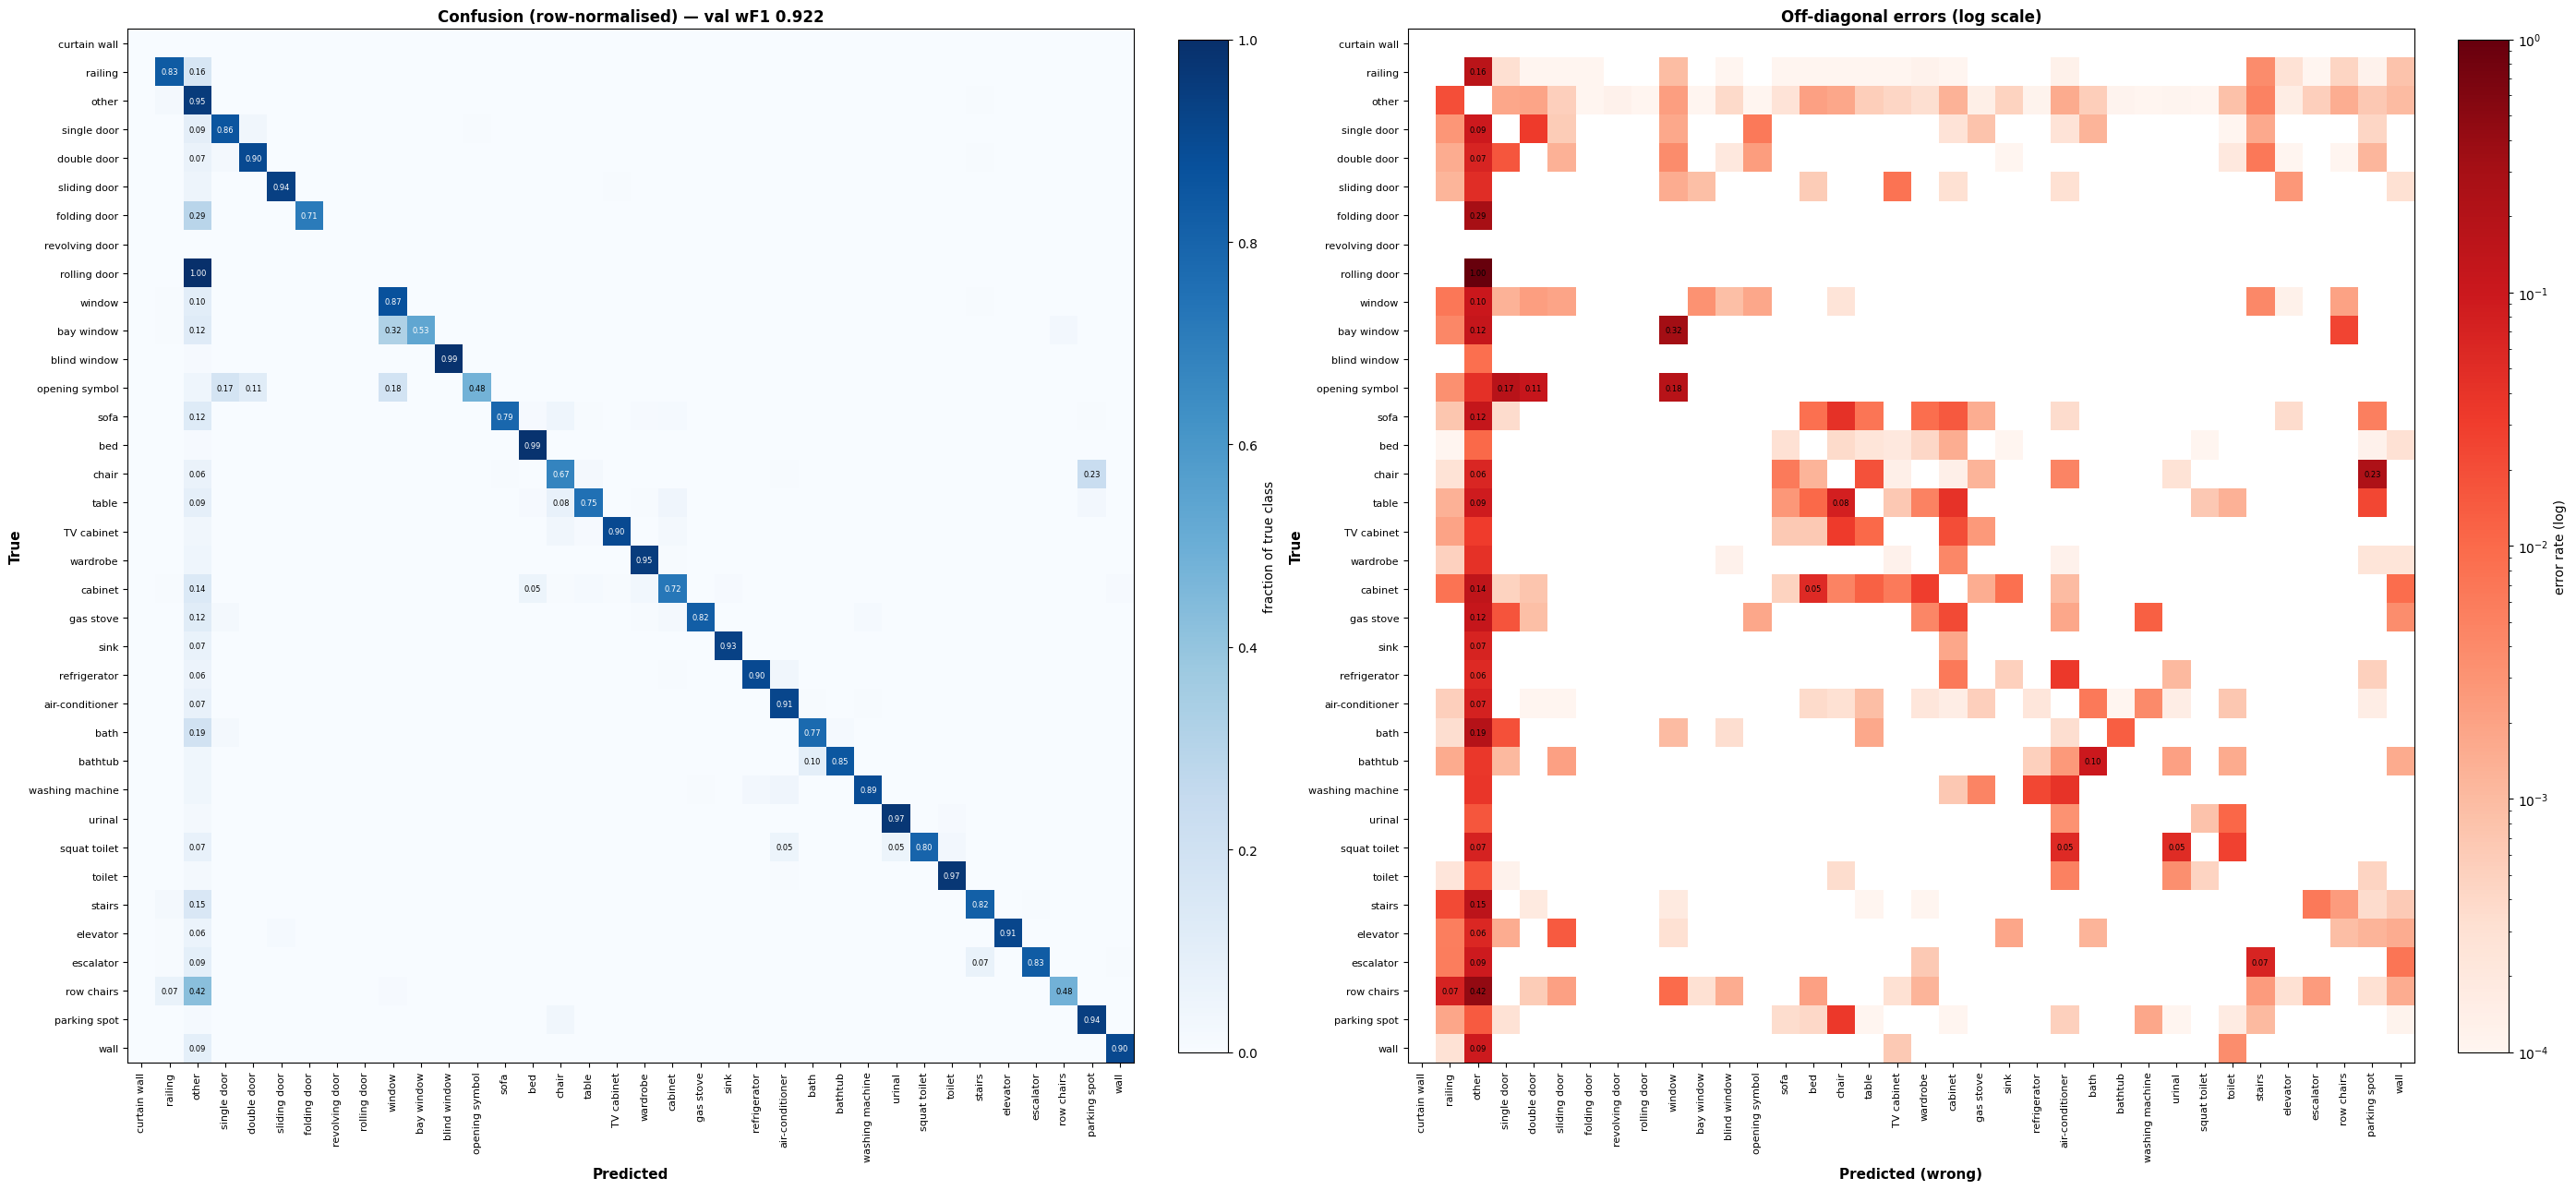


Top 20 confusion pairs
true                   predicted                 count      pct
-----------------------------------------------------------------
railing                other                    12,482    16.0%
other                  railing                   8,320     1.9%
other                  stairs                    2,175     0.5%
chair                  parking spot              1,712    23.3%
stairs                 other                     1,699    15.2%
row chairs             other                     1,402    42.2%
single door            other                     1,105     9.5%
wall                   other                       999     9.1%
other                  window                      988     0.2%
air-conditioner        other                       980     7.3%
other                  bed                         921     0.2%
window                 other                       827    10.3%
other                  double door                 804     0.2%
other         

,true_class,support,correct_pct,top_wrong,wrong_pct
0,rolling door,2,0.000000,other,100.000000
1,opening symbol,603,47.927032,window,18.407960
2,row chairs,3321,48.358928,other,42.216200
3,bay window,237,53.164557,window,32.067511
4,chair,7356,67.278412,parking spot,23.273518
5,folding door,41,70.731707,other,29.268293
6,cabinet,4109,72.426381,other,13.944999
7,table,3023,75.024810,other,8.699967
8,bath,3020,77.483444,other,18.973510
9,sofa,2771,78.599783,other,12.233851



Visualising: 0351-0025.svg


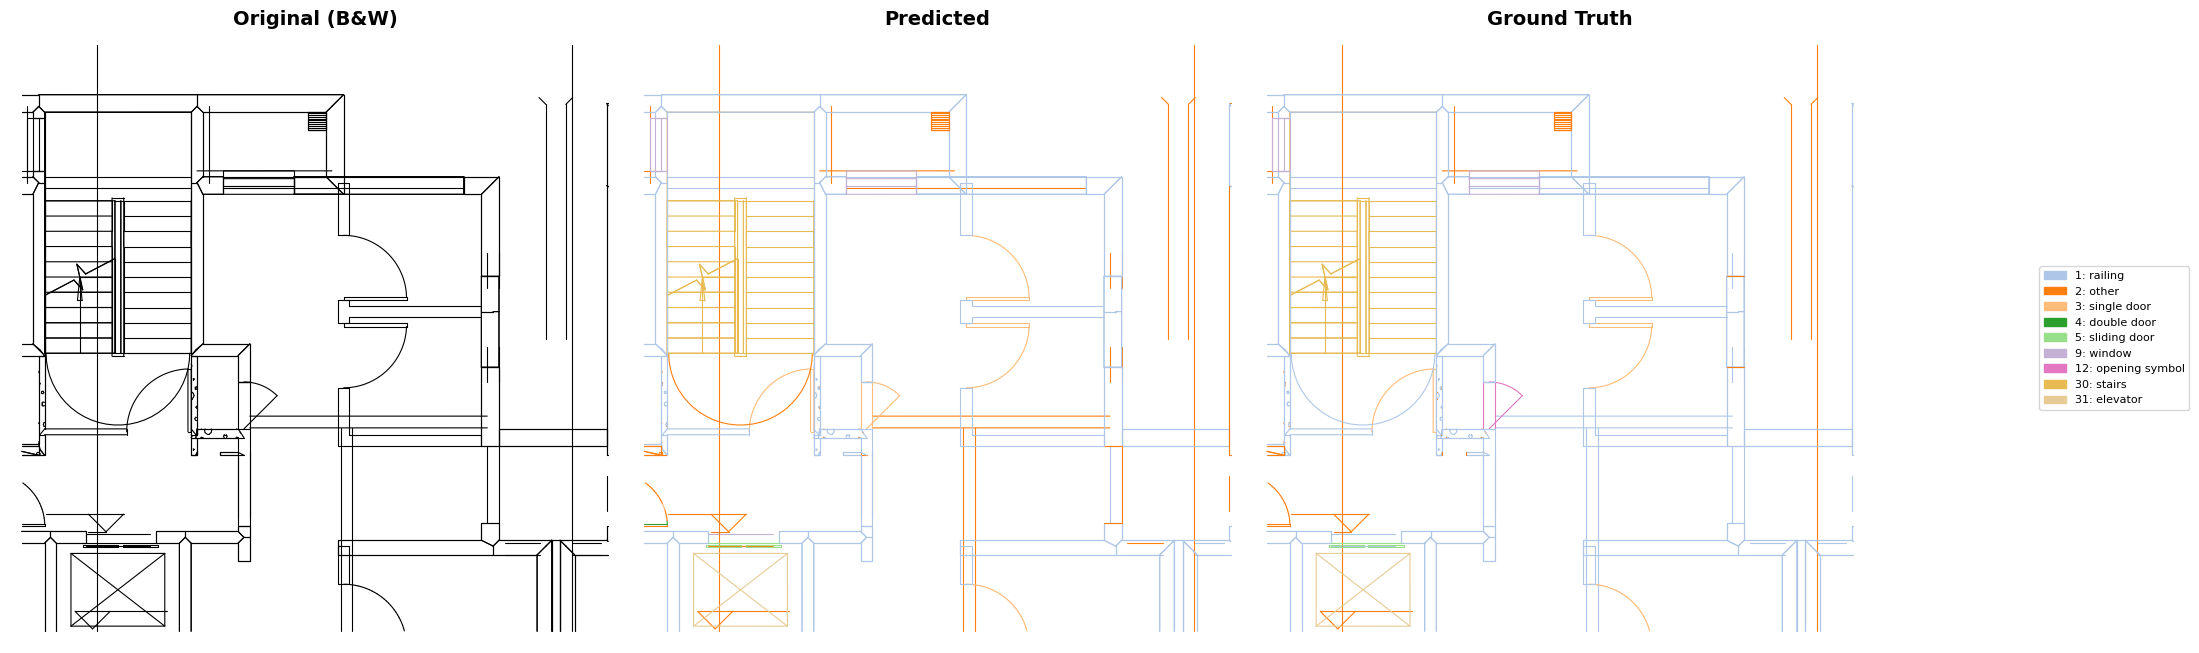


  drawing accuracy: 0.931 (689/740 paths)


test eval:   0%|          | 0/916 [00:00<?, ?it/s]


Channel ablation (val set)
config                            wF1    mF1    Δ wF1
--------------------------------------------------------


ablation:   0%|          | 0/7 [00:00<?, ?it/s]

full (knn+weld+delaunay)       0.9222 0.7992  +0.0000
no delaunay                    0.8584 0.6589  -0.0638
no knn                         0.7790 0.4137  -0.1432
no weld                        0.7361 0.4115  -0.1860
knn only                       0.6061 0.1372  -0.3161
weld only                      0.6242 0.1355  -0.2980
delaunay only                  0.5231 0.0615  -0.3990


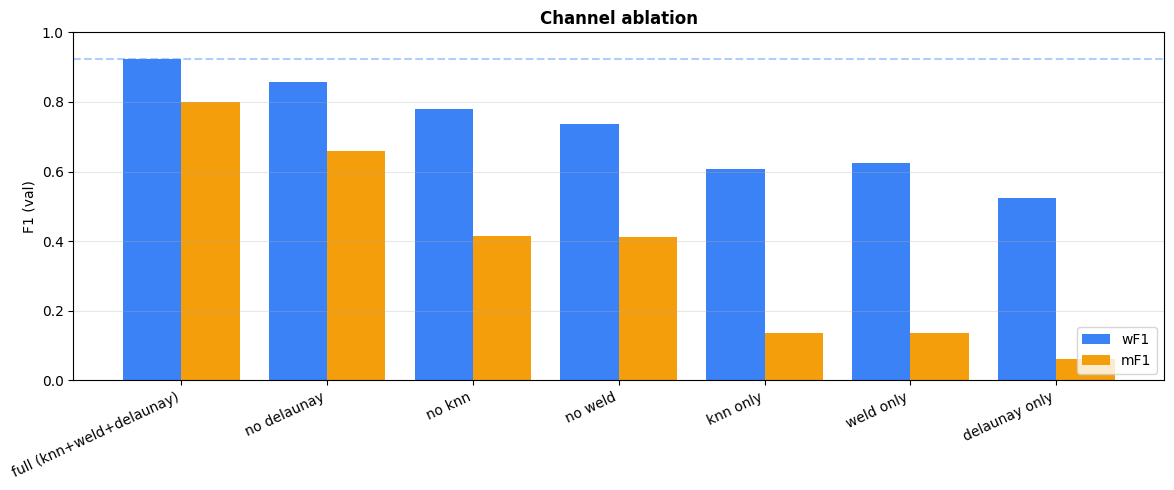


Feature importance (input-gradient saliency)


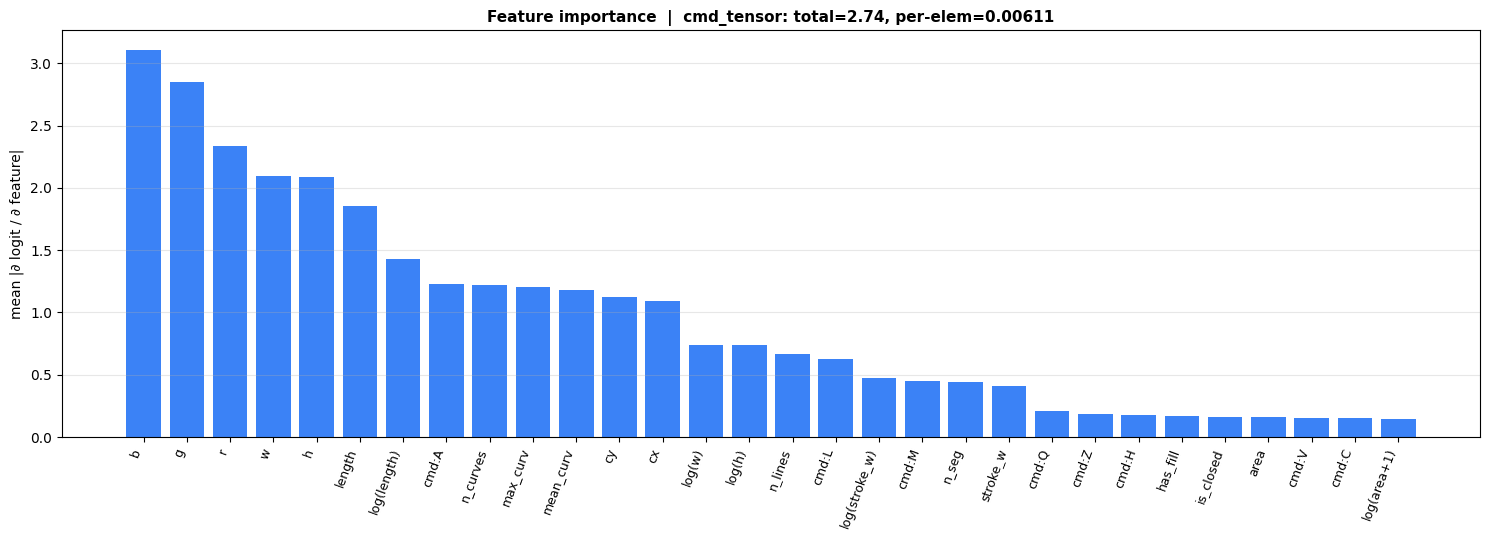


Top 10 most important geometric features:
   1. b              3.108
   2. g              2.851
   3. r              2.338
   4. w              2.092
   5. h              2.085
   6. length         1.851
   7. log(length)    1.426
   8. cmd:A          1.228
   9. n_curves       1.221
  10. max_curv       1.207

Bottom 5 (least important):
  26. is_closed      0.1624
  27. area           0.1584
  28. cmd:V          0.1543
  29. cmd:C          0.1513
  30. log(area+1)    0.1489

Artifacts saved under /content/drive/MyDrive/VectorGraphNET:
  confusion_counts_20260501_2013.csv
  confusion_normalised_20260501_2013.csv
  confusion_summary_20260501_2013.csv
  confusion_heatmaps_20260501_2013.png
  ablation_channels_20260501_2013.png
  feature_importance_20260501_2013.png


In [ ]:
# ============================================================
# 4. Results: confusion, visualisation, test eval, diagnostics
# ============================================================
# Updated for KNN + Weld + Delaunay hypergraph architecture.

CHECKPOINT_TO_LOAD = None
# CHECKPOINT_TO_LOAD = "/content/drive/MyDrive/VectorGraphNET/vgn_delaunay_hyper_colorblind.pt"

RUN_DIAGNOSTICS = True

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.collections import LineCollection
from matplotlib.colors import LogNorm
from sklearn.metrics import confusion_matrix
from datetime import datetime

CKPT_PATH = Path(CHECKPOINT_TO_LOAD) if CHECKPOINT_TO_LOAD else EXPERIMENT_CKPT
DRIVE_OUT = Path("/content/drive/MyDrive/VectorGraphNET")
DRIVE_OUT.mkdir(parents=True, exist_ok=True)

if not CKPT_PATH.exists():
    raise FileNotFoundError(
        f"No checkpoint at {CKPT_PATH}. Run Train cell or set CHECKPOINT_TO_LOAD.")

ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model"])
model.eval()

display(HTML(
    f"<div style='padding:10px 14px;background:#0f172a;color:#e5e7eb;"
    f"border-left:4px solid #38bdf8;font-family:monospace;font-size:13px;'>"
    f"<b>Loaded checkpoint</b><br>"
    f"epoch &nbsp;&nbsp; {ckpt.get('epoch','?')}<br>"
    f"val wF1 &nbsp; {ckpt.get('val_wf1',float('nan')):.4f}<br>"
    f"val mF1 &nbsp; {ckpt.get('val_mf1',float('nan')):.4f}<br>"
    f"path &nbsp;&nbsp;&nbsp; <code>{CKPT_PATH}</code>"
    f"</div>"))


# ------------------------------------------------------------------
# 4a. Confusion matrix on val_loader
# ------------------------------------------------------------------
val_loader = DataLoader(val_ds, batch_size=CFG.batch_size, shuffle=False, num_workers=0)

all_preds, all_gts = [], []
with torch.no_grad():
    for batch in tqdm(val_loader, desc="val confusion"):
        batch = batch.to(DEVICE)
        batch = maybe_zero_color(batch)
        out = model(batch)
        all_preds.append(out["fine"].argmax(-1).cpu().numpy())
        all_gts.append(batch["path"].y_fine.cpu().numpy())
preds = np.concatenate(all_preds)
gts   = np.concatenate(all_gts)

cm = confusion_matrix(gts, preds, labels=list(range(N_FINE)))
class_names = [FLOORPLANCAD_NAMES[i] for i in range(N_FINE)]

cm_counts = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_counts.index.name = "true"; cm_counts.columns.name = "predicted"
row_sums = cm.sum(axis=1, keepdims=True); row_sums[row_sums == 0] = 1
cm_norm = pd.DataFrame(cm / row_sums, index=class_names, columns=class_names)
cm_norm.index.name = "true"; cm_norm.columns.name = "predicted"

ts = datetime.now().strftime("%Y%m%d_%H%M")
counts_csv = DRIVE_OUT / f"confusion_counts_{ts}.csv"
norm_csv   = DRIVE_OUT / f"confusion_normalised_{ts}.csv"
cm_counts.to_csv(counts_csv)
cm_norm.to_csv(norm_csv, float_format="%.4f")


# ------------------------------------------------------------------
# 4b. Heatmaps
# ------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(28, 13))

im1 = ax1.imshow(cm_norm.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax1.set_xticks(range(N_FINE)); ax1.set_yticks(range(N_FINE))
ax1.set_xticklabels(class_names, rotation=90, fontsize=8)
ax1.set_yticklabels(class_names, fontsize=8)
ax1.set_xlabel("Predicted", fontsize=11, fontweight="bold")
ax1.set_ylabel("True", fontsize=11, fontweight="bold")
ax1.set_title(f"Confusion (row-normalised) — val wF1 {ckpt.get('val_wf1',float('nan')):.3f}",
              fontsize=12, fontweight="bold")
for i in range(N_FINE):
    for j in range(N_FINE):
        v = cm_norm.values[i, j]
        if v >= 0.05:
            ax1.text(j, i, f"{v:.2f}", ha="center", va="center",
                     fontsize=6, color=("white" if v > 0.5 else "black"))
plt.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04, label="fraction of true class")

cm_err = cm_norm.copy(); np.fill_diagonal(cm_err.values, 0)
nz = cm_err.values[cm_err.values > 0]
vmin = max(1e-4, nz.min()) if len(nz) else 1e-4
im2 = ax2.imshow(cm_err.values, cmap="Reds",
                 norm=LogNorm(vmin=vmin, vmax=max(cm_err.values.max(), vmin*10)),
                 aspect="auto")
ax2.set_xticks(range(N_FINE)); ax2.set_yticks(range(N_FINE))
ax2.set_xticklabels(class_names, rotation=90, fontsize=8)
ax2.set_yticklabels(class_names, fontsize=8)
ax2.set_xlabel("Predicted (wrong)", fontsize=11, fontweight="bold")
ax2.set_ylabel("True", fontsize=11, fontweight="bold")
ax2.set_title("Off-diagonal errors (log scale)", fontsize=12, fontweight="bold")
for i in range(N_FINE):
    for j in range(N_FINE):
        v = cm_err.values[i, j]
        if v >= 0.05:
            ax2.text(j, i, f"{v:.2f}", ha="center", va="center",
                     fontsize=6, color="black")
plt.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="error rate (log)")
plt.tight_layout()
heatmap_path = DRIVE_OUT / f"confusion_heatmaps_{ts}.png"
plt.savefig(heatmap_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()


# ------------------------------------------------------------------
# 4c. Top confusion pairs + per-class summary
# ------------------------------------------------------------------
print("\nTop 20 confusion pairs")
print(f"{'true':<22} {'predicted':<22} {'count':>8} {'pct':>8}")
print("-" * 65)
flat = np.argsort(cm.flatten())[::-1]
shown = 0
for idx in flat:
    if shown >= 20: break
    t, p = np.unravel_index(idx, cm.shape)
    if t == p: continue
    if cm[t, p] == 0: break
    pct = 100 * cm[t, p] / max(cm[t].sum(), 1)
    print(f"{class_names[t]:<22} {class_names[p]:<22} {cm[t,p]:>8,} {pct:>7.1f}%")
    shown += 1

rows = []
for i in range(N_FINE):
    tot = cm[i].sum()
    if tot == 0: continue
    row = cm[i].copy(); row[i] = 0; j = row.argmax()
    rows.append({"true_class": class_names[i], "support": int(tot),
                 "correct_pct": 100*cm[i,i]/tot,
                 "top_wrong": class_names[j], "wrong_pct": 100*row[j]/tot})
summary = pd.DataFrame(rows).sort_values("correct_pct")
display(HTML("<h4 style='margin-top:18px'>Per-class accuracy (sorted by hardest)</h4>"))
display(summary.reset_index(drop=True))
summary_csv = DRIVE_OUT / f"confusion_summary_{ts}.csv"
summary.to_csv(summary_csv, index=False)


# ------------------------------------------------------------------
# 4d. Visualisation: B&W → predicted → ground truth
# ------------------------------------------------------------------
def _sample_path_points(d_string, n_points=30):
    try:
        path = svgpathtools.parse_path(d_string)
    except: return None
    if len(path) == 0: return None
    pts = []
    for t in np.linspace(0, 1, n_points):
        try: p = path.point(t); pts.append((p.real, p.imag))
        except: pass
    return np.array(pts) if len(pts) >= 2 else None


def _build_colormap(n_classes):
    cmap1 = plt.colormaps.get_cmap("tab20")
    colors = [cmap1(i) for i in range(20)]
    if n_classes > 20:
        cmap2 = plt.colormaps.get_cmap("tab20b")
        colors += [cmap2(i) for i in range(n_classes - 20)]
    return colors[:n_classes]


def visualize_prediction(svg_path, model, device, figsize=(22, 8), linewidth=0.8):
    """Build graph matching current architecture (KNN+Weld+Delaunay hyper)."""
    raw = parse_svg_paths(svg_path)
    kept_f, kept_ct, kept_y, kept_pts = [], [], [], []
    for p in raw:
        f = path_features(p)
        if f is None: continue
        pts = _sample_path_points(p["d"])
        if pts is None: continue
        kept_f.append(f); kept_ct.append(f["cmd_tensor"])
        kept_y.append(p["semantic_id"]); kept_pts.append(pts)
    n = len(kept_f)
    if n < KNN_K + 1:
        print(f"  only {n} renderable paths — skipping"); return

    # Node features
    X = np.stack([f["feat"] for f in kept_f])
    Y = np.array(kept_y, dtype=np.int64)
    centers = np.array([f["center"] for f in kept_f], dtype=np.float32)
    cmin = centers.min(axis=0); cmax = centers.max(axis=0)
    span = float(max(cmax[0]-cmin[0], cmax[1]-cmin[1], 1e-6))
    bbox_diag = float(np.linalg.norm(cmax - cmin))
    cn = (centers - cmin) / span
    X[:,0]=cn[:,0]; X[:,1]=cn[:,1]; X[:,2]/=span; X[:,3]/=span

    # KNN edges
    nn_m = NearestNeighbors(n_neighbors=min(KNN_K+1, n)).fit(cn)
    _, idx = nn_m.kneighbors(cn)
    src, dst = [], []
    for i in range(n):
        for j in idx[i,1:]: src.append(i); dst.append(int(j))
    knn_ei = np.array([src, dst], dtype=np.int64)

    # Weld edges
    weld_ei = build_weld_edges(kept_f, eps_abs=bbox_diag*WELD_EPS_FRAC)

    # Delaunay triangles
    hyper_ei, num_tri, tri_pair_counts = build_delaunay_triangles(kept_f)

    # Edge features (11-dim with triangle counts)
    knn_ef  = _compute_edge_features(kept_f, knn_ei,  bbox_diag, tri_pair_counts)
    weld_ef = _compute_edge_features(kept_f, weld_ei, bbox_diag, tri_pair_counts)

    # Build HeteroData matching model's expected schema
    g = HeteroData()
    g["path"].x          = torch.from_numpy(X).float()
    g["path"].y          = torch.from_numpy(Y).long()
    g["path"].cmd_tensor = torch.from_numpy(np.stack(kept_ct)).float()

    g["path","knn","path"].edge_index  = torch.from_numpy(knn_ei).long()
    g["path","knn","path"].edge_attr   = torch.from_numpy(knn_ef).float()
    g["path","weld","path"].edge_index = torch.from_numpy(weld_ei).long()
    g["path","weld","path"].edge_attr  = torch.from_numpy(weld_ef).float()

    g["hedge"].x = torch.zeros(num_tri, 1)
    if hyper_ei.shape[1] > 0:
        g["path","in_triangle","hedge"].edge_index = torch.from_numpy(hyper_ei).long()
    else:
        g["path","in_triangle","hedge"].edge_index = torch.zeros((2,0), dtype=torch.long)

    # Zero colour if needed
    if ZERO_STROKE_COLOR:
        g["path"].x[:, list(RGB_INDICES)] = 0.0

    model.eval(); g = g.to(device)
    with torch.no_grad():
        out = model(g)
        preds_local = out["fine"].argmax(-1).cpu().numpy()
    gts_local = g["path"].y.cpu().numpy()

    assert len(preds_local) == len(kept_pts) == len(gts_local)

    colors = _build_colormap(N_FINE)
    pred_colors = [colors[int(p)] for p in preds_local]
    gt_colors   = [colors[int(y)] for y in gts_local]

    all_pts = np.concatenate(kept_pts)
    xmn,ymn = all_pts.min(axis=0); xmx,ymx = all_pts.max(axis=0)
    margin = max(xmx-xmn, ymx-ymn) * 0.02

    fig, axes = plt.subplots(1, 3, figsize=figsize)
    def draw(ax, pts, cs, title):
        lc = LineCollection(pts, colors=cs, linewidths=linewidth, capstyle="round")
        ax.add_collection(lc)
        ax.set_xlim(xmn-margin, xmx+margin); ax.set_ylim(ymx+margin, ymn-margin)
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(title, fontsize=14, fontweight="bold")
    draw(axes[0], kept_pts, ["black"]*len(kept_pts), "Original (B&W)")
    draw(axes[1], kept_pts, pred_colors, "Predicted")
    draw(axes[2], kept_pts, gt_colors,   "Ground Truth")

    present = sorted(set(preds_local.tolist()) | set(gts_local.tolist()))
    handles = [mpatches.Patch(color=colors[c],
               label=f"{c}: {FLOORPLANCAD_NAMES.get(c,'?')}") for c in present]
    fig.legend(handles=handles, loc="center right", fontsize=8, ncol=1,
               frameon=True, bbox_to_anchor=(1.0, 0.5))
    plt.tight_layout(); plt.subplots_adjust(right=0.85)
    out_png = DRIVE_OUT / f"segmentation_comparison_{ts}.png"
    plt.savefig(out_png, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

    correct = (preds_local == gts_local)
    print(f"\n  drawing accuracy: {correct.mean():.3f} "
          f"({correct.sum()}/{len(correct)} paths)")


# Pick a variety-rich drawing
sample_svg = train_svgs[0]
for svg in train_svgs[:30]:
    paths = parse_svg_paths(svg)
    if len(set(p["semantic_id"] for p in paths)) >= 5 and len(paths) > 100:
        sample_svg = svg; break
print(f"\nVisualising: {sample_svg.name}")
visualize_prediction(sample_svg, model, DEVICE)


# ------------------------------------------------------------------
# 4e. Test-set evaluation
# ------------------------------------------------------------------
test_loader = DataLoader(test_ds, batch_size=CFG.batch_size, shuffle=False, num_workers=0)
all_preds, all_gts = [], []
with torch.no_grad():
    for batch in tqdm(test_loader, desc="test eval"):
        batch = batch.to(DEVICE)
        batch = maybe_zero_color(batch)
        out = model(batch)
        all_preds.append(out["fine"].argmax(-1).cpu().numpy())
        all_gts.append(batch["path"].y_fine.cpu().numpy())
preds = np.concatenate(all_preds)
gts   = np.concatenate(all_gts)
test_wf1 = f1_score(gts, preds, average="weighted", zero_division=0)
test_mf1 = f1_score(gts, preds, average="macro",    zero_division=0)

display(HTML(
    f"<div style='padding:14px 16px;background:#0f172a;color:#e5e7eb;"
    f"border-left:4px solid #f59e0b;font-family:monospace;font-size:14px;"
    f"margin-top:18px;'>"
    f"<b>Test set</b> ({len(test_ds)} graphs)<br>"
    f"wF1 &nbsp;&nbsp; {test_wf1:.4f} &nbsp;&nbsp;<span style='color:#9ca3af'>(paper 0.890)</span><br>"
    f"mF1 &nbsp;&nbsp; {test_mf1:.4f} &nbsp;&nbsp;<span style='color:#9ca3af'>(paper 0.790)</span>"
    f"</div>"))


# ------------------------------------------------------------------
# 4f. Diagnostics: channel ablation + feature importance
# ------------------------------------------------------------------
diagnostics_artifacts = []

if RUN_DIAGNOSTICS:
    val_loader_diag = DataLoader(val_ds, batch_size=CFG.batch_size,
                                 shuffle=False, num_workers=0)

    # ---- Channel ablation ----
    # Three channels: KNN (pairwise), Weld (pairwise), Delaunay (hypergraph)
    # To ablate pairwise types: toggle model.pw_types
    # To ablate hypergraph: temporarily replace hyper_idx with empty tensor

    def eval_ablation(active_pw, use_hyper, name):
        """Evaluate with a subset of channels active."""
        saved_pw = model.pw_types
        model.pw_types = tuple(active_pw)

        # Monkey-patch _aggregate to skip hypergraph if disabled
        orig_agg = model._aggregate.__func__

        if not use_hyper:
            def _agg_no_hyper(self, gat_dict, hyper_layer, h, data):
                outs = []
                for et in self.pw_types:
                    ei = data["path", et, "path"].edge_index
                    ea = data["path", et, "path"].edge_attr
                    if ei.numel() == 0: continue
                    outs.append(gat_dict[et](h, ei, edge_attr=ea))
                return torch.stack(outs, dim=0).mean(dim=0) if outs else h
            model._aggregate = types.MethodType(_agg_no_hyper, model)

        try:
            all_p, all_g = [], []
            with torch.no_grad():
                for batch in val_loader_diag:
                    batch = batch.to(DEVICE)
                    batch = maybe_zero_color(batch)
                    out = model(batch)
                    all_p.append(out["fine"].argmax(-1).cpu().numpy())
                    all_g.append(batch["path"].y_fine.cpu().numpy())
            p = np.concatenate(all_p); g = np.concatenate(all_g)
            wf1 = f1_score(g, p, average="weighted", zero_division=0)
            mf1 = f1_score(g, p, average="macro",    zero_division=0)
            return wf1, mf1
        finally:
            model.pw_types = saved_pw
            model._aggregate = types.MethodType(orig_agg, model)

    ABLATION_CONFIGS = [
        ("full (knn+weld+delaunay)",  ("knn","weld"), True),
        ("no delaunay",               ("knn","weld"), False),
        ("no knn",                    ("weld",),      True),
        ("no weld",                   ("knn",),       True),
        ("knn only",                  ("knn",),       False),
        ("weld only",                 ("weld",),      False),
        ("delaunay only",             (),             True),
    ]

    print("\nChannel ablation (val set)")
    print(f"{'config':<30} {'wF1':>6} {'mF1':>6}  {'Δ wF1':>7}")
    print("-" * 56)
    abl_rows = []
    base_wf1 = None
    for name, pw, hyp in tqdm(ABLATION_CONFIGS, desc="ablation"):
        wf1, mf1 = eval_ablation(pw, hyp, name)
        if base_wf1 is None: base_wf1 = wf1
        delta = wf1 - base_wf1
        abl_rows.append((name, wf1, mf1, delta))
        print(f"{name:<30} {wf1:>6.4f} {mf1:>6.4f}  {delta:>+7.4f}")

    fig, ax = plt.subplots(figsize=(12, 5))
    names_abl = [r[0] for r in abl_rows]
    wf1s = [r[1] for r in abl_rows]; mf1s = [r[2] for r in abl_rows]
    x = np.arange(len(names_abl))
    ax.bar(x-0.2, wf1s, 0.4, label="wF1", color="#3b82f6")
    ax.bar(x+0.2, mf1s, 0.4, label="mF1", color="#f59e0b")
    if base_wf1: ax.axhline(base_wf1, color="#3b82f6", ls="--", alpha=0.4)
    ax.set_xticks(x); ax.set_xticklabels(names_abl, rotation=25, ha="right")
    ax.set_ylabel("F1 (val)"); ax.set_ylim(0, 1)
    ax.set_title("Channel ablation", fontsize=12, fontweight="bold")
    ax.legend(loc="lower right"); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    ablation_path = DRIVE_OUT / f"ablation_channels_{ts}.png"
    plt.savefig(ablation_path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    diagnostics_artifacts.append(ablation_path)

    # ---- Feature importance ----
    GEOM_FEATURE_NAMES = [
        "cx","cy","w","h","log(w)","log(h)","length","log(length)",
        "stroke_w","log(stroke_w)","r","g","b","has_fill",
        "n_seg","is_closed","n_lines","n_curves",
        "area","log(area+1)","mean_curv","max_curv",
        "cmd:M","cmd:L","cmd:H","cmd:V","cmd:C","cmd:Q","cmd:A","cmd:Z",
    ]
    assert len(GEOM_FEATURE_NAMES) == NODE_FEATURE_DIM

    print("\nFeature importance (input-gradient saliency)")
    model.eval()
    geom_grad_sum = torch.zeros(NODE_FEATURE_DIM, device=DEVICE)
    cmd_grad_sum  = torch.tensor(0., device=DEVICE)
    n_nodes_seen  = 0
    SAMPLE_BATCHES = 5

    for bi, batch in enumerate(val_loader_diag):
        if bi >= SAMPLE_BATCHES: break
        batch = batch.to(DEVICE)
        batch = maybe_zero_color(batch)
        x_in   = batch["path"].x.detach().clone().requires_grad_(True)
        cmd_in = batch["path"].cmd_tensor.detach().clone().requires_grad_(True)
        batch["path"].x = x_in; batch["path"].cmd_tensor = cmd_in
        out = model(batch)
        logits = out["fine"]
        target = logits.gather(1, logits.argmax(-1).unsqueeze(1)).sum()
        gx, gc = torch.autograd.grad(target, [x_in, cmd_in])
        geom_grad_sum += gx.abs().sum(dim=0)
        cmd_grad_sum  += gc.abs().sum()
        n_nodes_seen  += x_in.shape[0]

    geom_imp = (geom_grad_sum / max(n_nodes_seen, 1)).cpu().numpy()
    cmd_total = (cmd_grad_sum / max(n_nodes_seen, 1)).item()
    cmd_per   = cmd_total / float(MAX_CMDS * (CMD_DIM - 1))

    order = np.argsort(geom_imp)[::-1]
    fig, ax = plt.subplots(figsize=(15, 5.5))
    ax.bar(range(NODE_FEATURE_DIM), geom_imp[order], color="#3b82f6")
    ax.set_xticks(range(NODE_FEATURE_DIM))
    ax.set_xticklabels([GEOM_FEATURE_NAMES[i] for i in order],
                       rotation=70, ha="right", fontsize=9)
    ax.set_ylabel("mean |∂ logit / ∂ feature|")
    ax.set_title(f"Feature importance  |  cmd_tensor: total={cmd_total:.3g}, "
                 f"per-elem={cmd_per:.3g}", fontsize=11, fontweight="bold")
    ax.grid(axis="y", alpha=0.3); plt.tight_layout()
    feat_path = DRIVE_OUT / f"feature_importance_{ts}.png"
    plt.savefig(feat_path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    diagnostics_artifacts.append(feat_path)

    print("\nTop 10 most important geometric features:")
    for rank, idx in enumerate(order[:10]):
        print(f"  {rank+1:>2}. {GEOM_FEATURE_NAMES[idx]:<14} {geom_imp[idx]:.4g}")
    print("\nBottom 5 (least important):")
    for rank, idx in enumerate(order[-5:]):
        print(f"  {NODE_FEATURE_DIM-4+rank:>2}. {GEOM_FEATURE_NAMES[idx]:<14} {geom_imp[idx]:.4g}")

print(f"\nArtifacts saved under {DRIVE_OUT}:")
for p in [counts_csv, norm_csv, summary_csv, heatmap_path] + diagnostics_artifacts:
    print(f"  {p.name}")

Checkpoint: epoch 67, val wF1 0.9222, val mF1 0.7992


test inference:   0%|          | 0/916 [00:00<?, ?it/s]

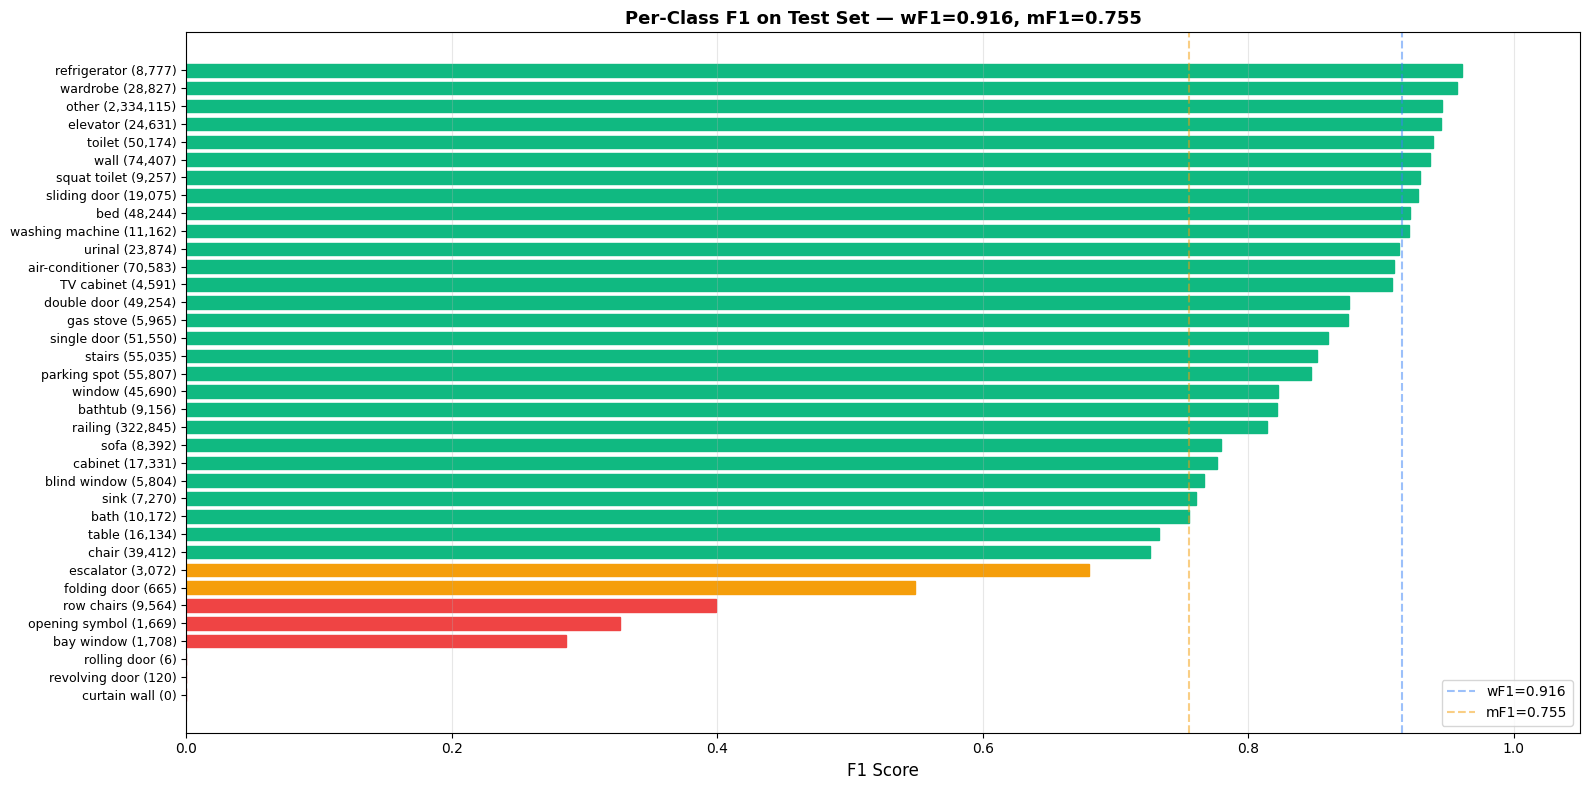

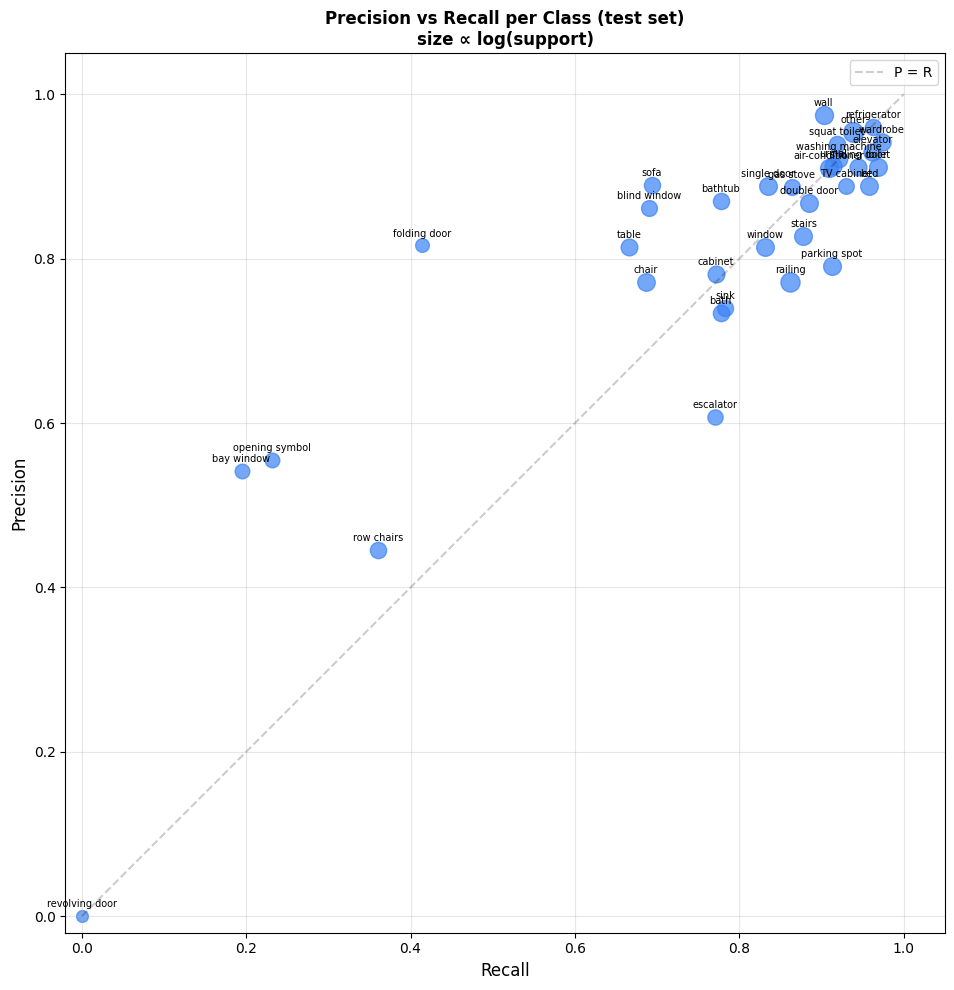

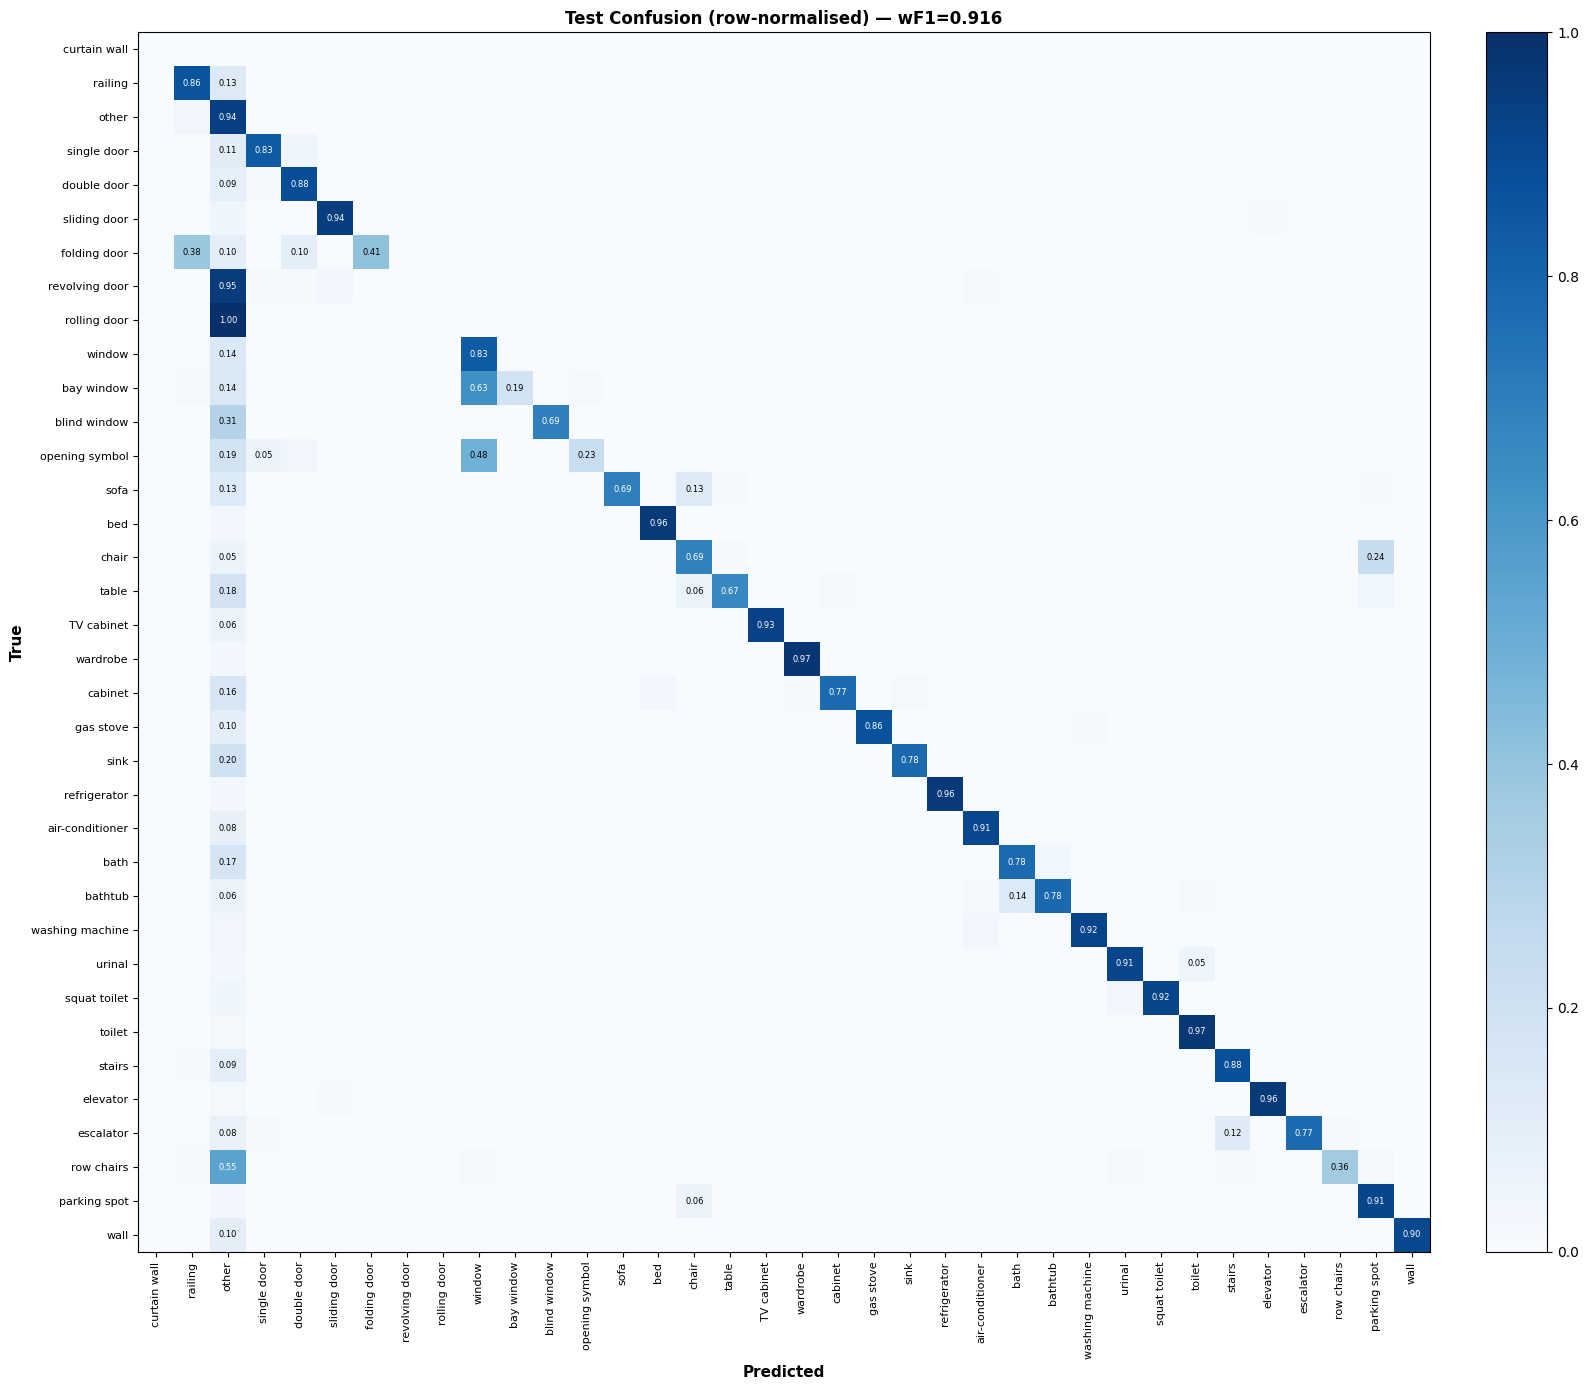


Top 15 confusion pairs (test set)
True                   Predicted                 Count        %
-----------------------------------------------------------------
other                  railing                  80,048     3.4%
railing                other                    42,555    13.2%
chair                  parking spot              9,333    23.7%
other                  stairs                    8,418     0.4%
wall                   other                     7,107     9.6%
window                 other                     6,396    14.0%
other                  window                    6,036     0.3%
single door            other                     5,827    11.3%
air-conditioner        other                     5,660     8.0%
row chairs             other                     5,267    55.1%
stairs                 other                     5,225     9.5%
other                  air-conditioner           5,186     0.2%
other                  bed                       4,934     0.2%
dou

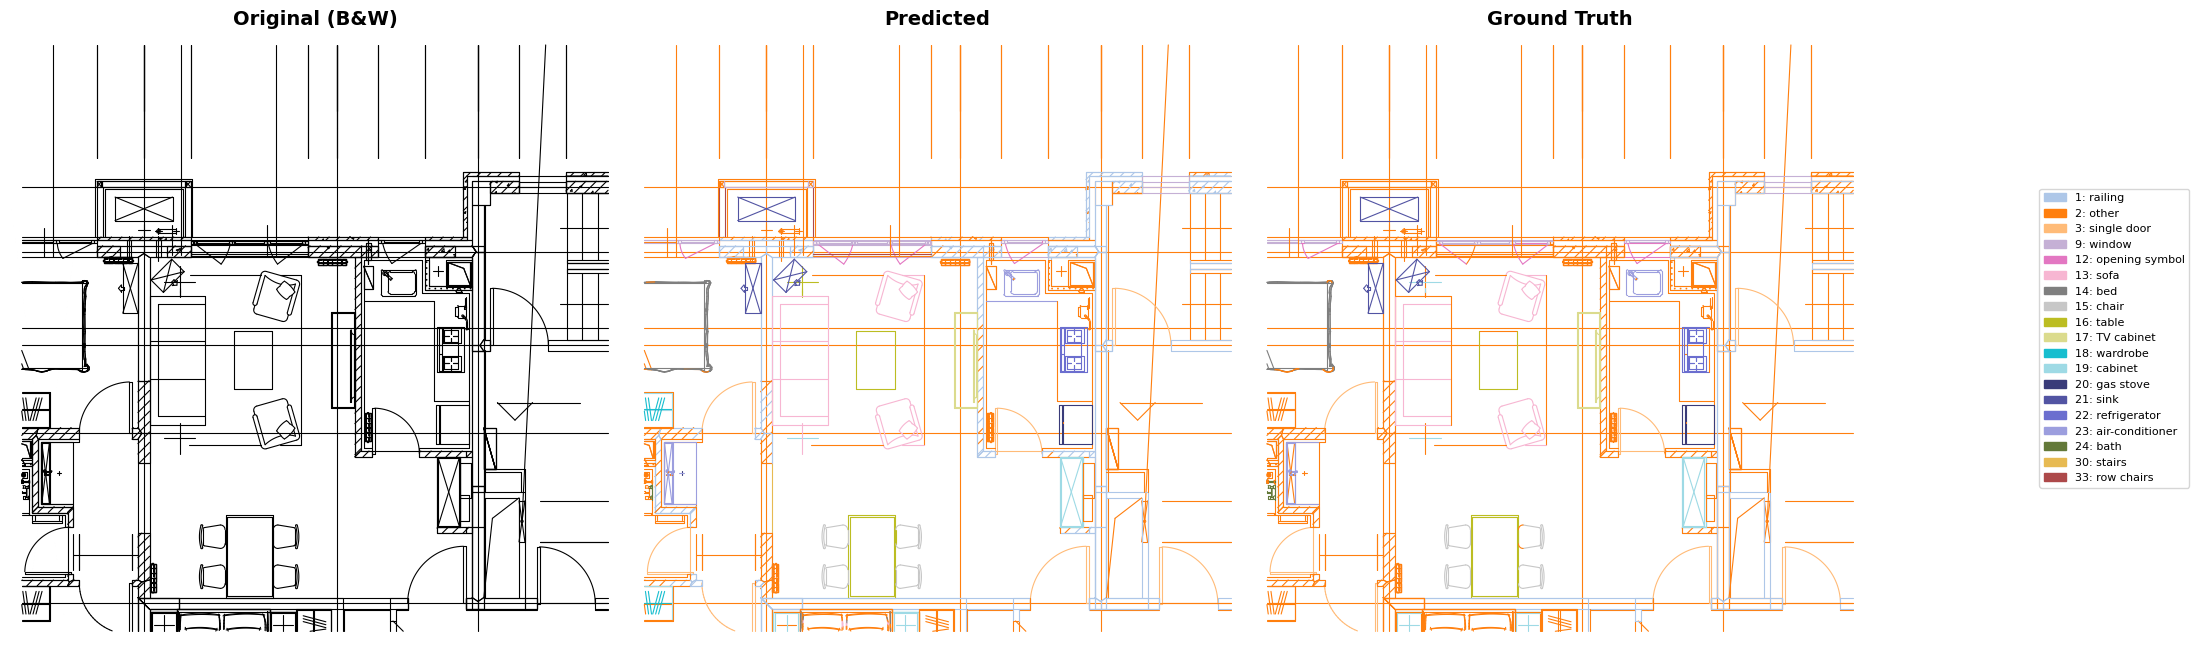


  drawing accuracy: 0.871 (3987/4575)

FULL PER-CLASS REPORT (test set)
                 precision    recall  f1-score   support

   curtain wall      0.000     0.000     0.000         0
        railing      0.772     0.862     0.814    322845
          other      0.954     0.938     0.946   2334115
    single door      0.888     0.835     0.860     51550
    double door      0.868     0.885     0.876     49254
   sliding door      0.912     0.945     0.928     19075
   folding door      0.816     0.414     0.549       665
 revolving door      0.000     0.000     0.000       120
   rolling door      0.000     0.000     0.000         6
         window      0.814     0.831     0.823     45690
     bay window      0.542     0.194     0.286      1708
   blind window      0.862     0.691     0.767      5804
 opening symbol      0.555     0.231     0.327      1669
           sofa      0.889     0.694     0.779      8392
            bed      0.889     0.958     0.922     48244
          chai

In [ ]:
# ============================================================
# 5. Test Set Deep Dive
# ============================================================
# Run this AFTER training completes. Produces:
#   - Headline metrics (wF1, mF1, accuracy)
#   - Per-class F1 bar chart
#   - Confusion heatmap (test-specific)
#   - B&W → Predicted → GT visualization on a test drawing
#   - Per-class precision vs recall scatter
#   - All artifacts saved to Drive

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.collections import LineCollection
from matplotlib.colors import LogNorm
from sklearn.metrics import confusion_matrix, classification_report
from datetime import datetime

DRIVE_OUT = Path("/content/drive/MyDrive/VectorGraphNET")
ts = datetime.now().strftime("%Y%m%d_%H%M")

# ---- Load best checkpoint ----
CKPT_PATH = EXPERIMENT_CKPT
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model"])
model.eval()
print(f"Checkpoint: epoch {ckpt.get('epoch','?')}, "
      f"val wF1 {ckpt.get('val_wf1',0):.4f}, val mF1 {ckpt.get('val_mf1',0):.4f}")


# ==================================================================
# 5a. Test inference
# ==================================================================
test_loader = DataLoader(test_ds, batch_size=CFG.batch_size,
                         shuffle=False, num_workers=0)

all_preds, all_gts = [], []
all_probs = []
with torch.no_grad():
    for batch in tqdm(test_loader, desc="test inference"):
        batch = batch.to(DEVICE)
        batch = maybe_zero_color(batch)
        out = model(batch)
        probs = F.softmax(out["fine"], dim=-1)
        all_preds.append(out["fine"].argmax(-1).cpu().numpy())
        all_probs.append(probs.max(-1).values.cpu().numpy())
        all_gts.append(batch["path"].y_fine.cpu().numpy())

preds = np.concatenate(all_preds)
gts   = np.concatenate(all_gts)
probs = np.concatenate(all_probs)

test_wf1 = f1_score(gts, preds, average="weighted", zero_division=0)
test_mf1 = f1_score(gts, preds, average="macro",    zero_division=0)
test_acc = (preds == gts).mean()

class_names = [FLOORPLANCAD_NAMES[i] for i in range(N_FINE)]


# ==================================================================
# 5b. Headline banner
# ==================================================================
display(HTML(
    f"<div style='padding:16px 20px;background:#0f172a;color:#e5e7eb;"
    f"border-left:4px solid #10b981;font-family:monospace;font-size:15px;"
    f"margin:12px 0;'>"
    f"<b>TEST SET RESULTS</b> &nbsp; ({len(test_ds):,} graphs, "
    f"{len(gts):,} paths)<br><br>"
    f"<table style='color:#e5e7eb;font-size:14px;'>"
    f"<tr><td>wF1</td><td>&nbsp;&nbsp;</td>"
    f"<td><b>{test_wf1:.4f}</b></td><td>&nbsp;&nbsp;</td>"
    f"<td style='color:#9ca3af'>paper: 0.890</td>"
    f"<td>&nbsp;&nbsp;</td>"
    f"<td style='color:{'#10b981' if test_wf1>=0.890 else '#ef4444'}'>"
    f"{'✓ BEATS' if test_wf1>=0.890 else '✗ below'}</td></tr>"
    f"<tr><td>mF1</td><td></td>"
    f"<td><b>{test_mf1:.4f}</b></td><td></td>"
    f"<td style='color:#9ca3af'>paper: 0.790</td>"
    f"<td></td>"
    f"<td style='color:{'#10b981' if test_mf1>=0.790 else '#ef4444'}'>"
    f"{'✓ BEATS' if test_mf1>=0.790 else '✗ below'}</td></tr>"
    f"<tr><td>acc</td><td></td><td><b>{test_acc:.4f}</b></td></tr>"
    f"</table></div>"))


# ==================================================================
# 5c. Per-class F1 bar chart
# ==================================================================
report_dict = classification_report(
    gts, preds, target_names=class_names,
    labels=list(range(N_FINE)), output_dict=True, zero_division=0)

rows = []
for i, name in enumerate(class_names):
    if name in report_dict:
        r = report_dict[name]
        rows.append({"class": name, "id": i, "support": int(r["support"]),
                     "precision": r["precision"], "recall": r["recall"],
                     "f1": r["f1-score"]})
df = pd.DataFrame(rows)
df_sorted = df.sort_values("f1", ascending=True)

fig, ax = plt.subplots(figsize=(16, 8))
y_pos = np.arange(len(df_sorted))
bars = ax.barh(y_pos, df_sorted["f1"].values, color="#3b82f6", height=0.7)

# Color bars by performance
for bar, f1_val in zip(bars, df_sorted["f1"].values):
    if f1_val < 0.5:
        bar.set_color("#ef4444")      # red: weak
    elif f1_val < 0.7:
        bar.set_color("#f59e0b")      # amber: moderate
    else:
        bar.set_color("#10b981")      # green: strong

ax.set_yticks(y_pos)
ax.set_yticklabels([f"{r['class']} ({r['support']:,})" for _, r in df_sorted.iterrows()],
                   fontsize=9)
ax.set_xlabel("F1 Score", fontsize=12)
ax.set_title(f"Per-Class F1 on Test Set — wF1={test_wf1:.3f}, mF1={test_mf1:.3f}",
             fontsize=13, fontweight="bold")
ax.axvline(test_wf1, color="#3b82f6", ls="--", alpha=0.5, label=f"wF1={test_wf1:.3f}")
ax.axvline(test_mf1, color="#f59e0b", ls="--", alpha=0.5, label=f"mF1={test_mf1:.3f}")
ax.set_xlim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
f1_chart_path = DRIVE_OUT / f"test_perclass_f1_{ts}.png"
plt.savefig(f1_chart_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()


# ==================================================================
# 5d. Precision vs Recall scatter
# ==================================================================
fig, ax = plt.subplots(figsize=(10, 10))
for _, r in df.iterrows():
    if r["support"] < 10:
        continue
    size = np.clip(np.log(r["support"] + 1) * 15, 20, 200)
    ax.scatter(r["recall"], r["precision"], s=size, alpha=0.7, color="#3b82f6")
    ax.annotate(r["class"], (r["recall"], r["precision"]),
                fontsize=7, ha="center", va="bottom",
                textcoords="offset points", xytext=(0, 5))

ax.plot([0, 1], [0, 1], "k--", alpha=0.2, label="P = R")
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision vs Recall per Class (test set)\n"
             "size ∝ log(support)", fontsize=12, fontweight="bold")
ax.set_xlim(-0.02, 1.05); ax.set_ylim(-0.02, 1.05)
ax.legend(); ax.grid(alpha=0.3)
ax.set_aspect("equal")
plt.tight_layout()
pr_chart_path = DRIVE_OUT / f"test_precision_recall_{ts}.png"
plt.savefig(pr_chart_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()


# ==================================================================
# 5e. Confusion heatmap (test set)
# ==================================================================
cm = confusion_matrix(gts, preds, labels=list(range(N_FINE)))
row_sums = cm.sum(axis=1, keepdims=True); row_sums[row_sums == 0] = 1
cm_norm = cm / row_sums

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(N_FINE)); ax.set_yticks(range(N_FINE))
ax.set_xticklabels(class_names, rotation=90, fontsize=8)
ax.set_yticklabels(class_names, fontsize=8)
ax.set_xlabel("Predicted", fontsize=11, fontweight="bold")
ax.set_ylabel("True", fontsize=11, fontweight="bold")
ax.set_title(f"Test Confusion (row-normalised) — wF1={test_wf1:.3f}",
             fontsize=12, fontweight="bold")
for i in range(N_FINE):
    for j in range(N_FINE):
        v = cm_norm[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    fontsize=6, color=("white" if v > 0.5 else "black"))
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
cm_chart_path = DRIVE_OUT / f"test_confusion_{ts}.png"
plt.savefig(cm_chart_path, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()


# ==================================================================
# 5f. Top confusion pairs
# ==================================================================
print("\nTop 15 confusion pairs (test set)")
print(f"{'True':<22} {'Predicted':<22} {'Count':>8} {'%':>8}")
print("-" * 65)
np.fill_diagonal(cm, 0)
flat = np.argsort(cm.flatten())[::-1]
shown = 0
gt_counts = np.bincount(gts, minlength=N_FINE)
for idx in flat:
    if shown >= 15: break
    t, p = np.unravel_index(idx, cm.shape)
    if cm[t, p] == 0: break
    pct = 100 * cm[t, p] / max(gt_counts[t], 1)
    print(f"{class_names[t]:<22} {class_names[p]:<22} {cm[t,p]:>8,} {pct:>7.1f}%")
    shown += 1


# ==================================================================
# 5g. Visualize on a TEST drawing (not train)
# ==================================================================
def _sample_path_points(d_string, n_points=30):
    try: path = svgpathtools.parse_path(d_string)
    except: return None
    if len(path) == 0: return None
    pts = []
    for t in np.linspace(0, 1, n_points):
        try: p = path.point(t); pts.append((p.real, p.imag))
        except: pass
    return np.array(pts) if len(pts) >= 2 else None

def _build_colormap(n):
    cmap1 = plt.colormaps.get_cmap("tab20")
    colors = [cmap1(i) for i in range(20)]
    if n > 20:
        cmap2 = plt.colormaps.get_cmap("tab20b")
        colors += [cmap2(i) for i in range(n - 20)]
    return colors[:n]

def visualize_test(svg_path, model, device, figsize=(22, 8), linewidth=0.8):
    raw = parse_svg_paths(svg_path)
    kept_f, kept_ct, kept_y, kept_pts = [], [], [], []
    for p in raw:
        f = path_features(p)
        if f is None: continue
        pts = _sample_path_points(p["d"])
        if pts is None: continue
        kept_f.append(f); kept_ct.append(f["cmd_tensor"])
        kept_y.append(p["semantic_id"]); kept_pts.append(pts)
    n = len(kept_f)
    if n < KNN_K + 1:
        print(f"  only {n} paths — skipping"); return

    X = np.stack([f["feat"] for f in kept_f])
    Y = np.array(kept_y, dtype=np.int64)
    centers = np.array([f["center"] for f in kept_f], dtype=np.float32)
    cmin = centers.min(axis=0); cmax = centers.max(axis=0)
    span = float(max(cmax[0]-cmin[0], cmax[1]-cmin[1], 1e-6))
    bbox_diag = float(np.linalg.norm(cmax - cmin))
    cn = (centers - cmin) / span
    X[:,0]=cn[:,0]; X[:,1]=cn[:,1]; X[:,2]/=span; X[:,3]/=span

    # KNN
    nn_m = NearestNeighbors(n_neighbors=min(KNN_K+1,n)).fit(cn)
    _, idx = nn_m.kneighbors(cn)
    src, dst = [], []
    for i in range(n):
        for j in idx[i,1:]: src.append(i); dst.append(int(j))
    knn_ei = np.array([src,dst], dtype=np.int64)

    # Weld
    weld_ei = build_weld_edges(kept_f, eps_abs=bbox_diag*WELD_EPS_FRAC)

    # Delaunay
    hyper_ei, num_tri, tri_pair_counts = build_delaunay_triangles(kept_f)

    # Edge features
    knn_ef  = _compute_edge_features(kept_f, knn_ei,  bbox_diag, tri_pair_counts)
    weld_ef = _compute_edge_features(kept_f, weld_ei, bbox_diag, tri_pair_counts)

    g = HeteroData()
    g["path"].x          = torch.from_numpy(X).float()
    g["path"].y          = torch.from_numpy(Y).long()
    g["path"].cmd_tensor = torch.from_numpy(np.stack(kept_ct)).float()
    g["path","knn","path"].edge_index  = torch.from_numpy(knn_ei).long()
    g["path","knn","path"].edge_attr   = torch.from_numpy(knn_ef).float()
    g["path","weld","path"].edge_index = torch.from_numpy(weld_ei).long()
    g["path","weld","path"].edge_attr  = torch.from_numpy(weld_ef).float()
    g["hedge"].x = torch.zeros(num_tri, 1)
    if hyper_ei.shape[1] > 0:
        g["path","in_triangle","hedge"].edge_index = torch.from_numpy(hyper_ei).long()
    else:
        g["path","in_triangle","hedge"].edge_index = torch.zeros((2,0), dtype=torch.long)

    if ZERO_STROKE_COLOR:
        g["path"].x[:, list(RGB_INDICES)] = 0.0

    model.eval(); g = g.to(device)
    with torch.no_grad():
        out = model(g)
        pred_local = out["fine"].argmax(-1).cpu().numpy()
    gt_local = g["path"].y.cpu().numpy()

    colors = _build_colormap(N_FINE)
    pred_colors = [colors[int(p)] for p in pred_local]
    gt_colors   = [colors[int(y)] for y in gt_local]

    all_pts = np.concatenate(kept_pts)
    xmn,ymn = all_pts.min(axis=0); xmx,ymx = all_pts.max(axis=0)
    margin = max(xmx-xmn, ymx-ymn) * 0.02

    fig, axes = plt.subplots(1, 3, figsize=figsize)
    def draw(ax, pts, cs, title):
        lc = LineCollection(pts, colors=cs, linewidths=linewidth, capstyle="round")
        ax.add_collection(lc)
        ax.set_xlim(xmn-margin, xmx+margin); ax.set_ylim(ymx+margin, ymn-margin)
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(title, fontsize=14, fontweight="bold")
    draw(axes[0], kept_pts, ["black"]*len(kept_pts), "Original (B&W)")
    draw(axes[1], kept_pts, pred_colors, "Predicted")
    draw(axes[2], kept_pts, gt_colors,   "Ground Truth")

    present = sorted(set(pred_local.tolist()) | set(gt_local.tolist()))
    handles = [mpatches.Patch(color=colors[c],
               label=f"{c}: {FLOORPLANCAD_NAMES.get(c,'?')}") for c in present]
    fig.legend(handles=handles, loc="center right", fontsize=8,
               ncol=1, frameon=True, bbox_to_anchor=(1.0, 0.5))
    plt.tight_layout(); plt.subplots_adjust(right=0.85)
    out_png = DRIVE_OUT / f"test_segmentation_{ts}.png"
    plt.savefig(out_png, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()

    correct = (pred_local == gt_local)
    print(f"\n  drawing accuracy: {correct.mean():.3f} ({correct.sum()}/{len(correct)})")
    return out_png


# Pick a test drawing with variety
test_viz_svg = test_svg_files[0]
for svg in test_svg_files[:50]:
    paths = parse_svg_paths(svg)
    n_cls = len(set(p["semantic_id"] for p in paths))
    if n_cls >= 5 and len(paths) > 100:
        test_viz_svg = svg; break

print(f"\nVisualising TEST drawing: {test_viz_svg.name}")
seg_path = visualize_test(test_viz_svg, model, DEVICE)


# ==================================================================
# 5h. Summary table
# ==================================================================
print("\n" + "=" * 65)
print("FULL PER-CLASS REPORT (test set)")
print("=" * 65)
print(classification_report(
    gts, preds, target_names=class_names,
    labels=list(range(N_FINE)), digits=3, zero_division=0))

# Save CSV
df.to_csv(DRIVE_OUT / f"test_perclass_{ts}.csv", index=False)

print(f"\nAll test artifacts saved to {DRIVE_OUT}:")
for name in [f"test_perclass_f1_{ts}.png",
             f"test_precision_recall_{ts}.png",
             f"test_confusion_{ts}.png",
             f"test_segmentation_{ts}.png",
             f"test_perclass_{ts}.csv"]:
    print(f"  {name}")